In [135]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import pandas as pd
import psycopg2

conn = psycopg2.connect(
    host="localhost", port=5432, dbname="pro2d_db", user="postgres", password="postgres"
)

df = pd.read_sql("SELECT * FROM events", conn)
conn.close()

print("=== Spalten im DataFrame ===")
print(df.columns.tolist())
print(f"\nZeilen: {len(df)}, Spalten: {len(df.columns)}")

C:\Users\janis\AppData\Local\Temp\ipykernel_46024\2819099016.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT * FROM events", conn)


=== Spalten im DataFrame ===
['Datum', 'Prio', 'Msr', 'Ort', 'Objekt', 'Meldung', 'Zustand', 'Benutzer', 'evtID', 'evtTyp']

Zeilen: 1054556, Spalten: 10


In [136]:
# Wie oft kommen evtIDs mehrfach vor?
id_counts = df["evtID"].value_counts()
print(f"evtIDs die nur 1x vorkommen: {(id_counts == 1).sum()}")
print(f"evtIDs die >1x vorkommen:    {(id_counts > 1).sum()}")
print("\nTop 10 häufigste evtIDs:")
print(id_counts.head(10).to_string())

# Beispiel: Was steckt hinter einer mehrfachen evtID?
top_id = id_counts.index[0]
print(f"\nBeispiel evtID {top_id}:")
print(
    df[df["evtID"] == top_id][
        ["Datum", "Msr", "Objekt", "Meldung", "Zustand", "Benutzer", "evtTyp"]
    ]
    .head(10)
    .to_string()
)

evtIDs die nur 1x vorkommen: 115516
evtIDs die >1x vorkommen:    249101

Top 10 häufigste evtIDs:
evtID
362009    6
361513    6
390038    6
389538    6
389039    6
387540    6
383539    6
383040    6
382540    6
380042    6

Beispiel evtID 362009:
                        Datum     Msr          Objekt                                         Meldung      Zustand Benutzer         evtTyp
47182 2016-03-03 11:46:22.459  MI-156  Feuchte Abluft  Drahtbruch - Messbereich um 10% unterschritten     Freigabe     AUTO  Störmeldungen
47183 2016-03-03 11:46:22.458  MI-156  Feuchte Abluft  Drahtbruch - Messbereich um 10% unterschritten  Quittierung     AUTO  Störmeldungen
47184 2016-03-03 11:46:22.459  MI-156  Feuchte Abluft  Drahtbruch - Messbereich um 10% unterschritten     Freigabe     AUTO  Störmeldungen
47185 2016-03-03 11:46:22.458  MI-156  Feuchte Abluft  Drahtbruch - Messbereich um 10% unterschritten  Quittierung     AUTO  Störmeldungen
47221 2016-03-03 11:46:12.760  MI-156  Feuchte Abluft  Dr

In [137]:
# === Datum Analyse ===
datum_counts = df["Datum"].value_counts()
print(f"Datums die nur 1x vorkommen: {(datum_counts == 1).sum()}")
print(f"Datums die >1x vorkommen:    {(datum_counts > 1).sum()}")
print("\nTop 10 häufigste Zeitstempel:")
print(datum_counts.head(10).to_string())

top_datum = datum_counts.index[0]
print(f"\nBeispiel Datum {top_datum}:")
print(
    df[df["Datum"] == top_datum][
        ["Datum", "Msr", "Objekt", "Meldung", "Zustand", "Benutzer", "evtTyp"]
    ].to_string()
)

Datums die nur 1x vorkommen: 935875
Datums die >1x vorkommen:    36737

Top 10 häufigste Zeitstempel:
Datum
2019-06-29 23:32:58.460    89
2017-10-16 08:13:04.010    87
2025-12-04 13:59:22.882    80
2017-10-16 08:08:36.360    78
2018-02-26 09:28:41.570    76
2020-08-12 10:58:18.522    76
2020-08-12 10:42:26.982    74
2019-06-30 00:52:58.410    72
2025-12-04 15:18:31.830    69
2019-06-30 00:52:58.730    63

Beispiel Datum 2019-06-29 23:32:58.460000:
                         Datum        Msr                                  Objekt                                         Meldung Zustand Benutzer         evtTyp
662424 2019-06-29 23:32:58.460    TIC-160                   Temperatur Kühlwasser                                             NaN   Kommt      NaN   Nicht bereit
662665 2019-06-29 23:32:58.460     TI-185                    Granulattemperatur 1                                             NaN   Kommt      NaN   Nicht bereit
662666 2019-06-29 23:32:58.460     TI-185                    G

In [138]:
for col in [
    "Prio",
    "Msr",
    "Ort",
    "Objekt",
    "Meldung",
    "Zustand",
    "Benutzer",
    "evtTyp",
    "Datum",
    "evtID",
]:
    print(f"\n{'=' * 40}")
    print(f"Spalte: {col}")
    print(f"Anzahl unique: {df[col].nunique(dropna=False)}")
    print(f"{'=' * 40}")
    print(df[col].unique())


Spalte: Prio
Anzahl unique: 4
[ 0. nan  1.  2.]

Spalte: Msr
Anzahl unique: 690
<StringArray>
['PARA-1810', 'PARA-1809', 'PARA-1700', 'PARA-3531', 'PARA-3584', 'PARA-3507',
 'PARA-3515', 'PARA-2006', 'PARA-2014', 'PARA-2300',
 ...
    'TT-550',    'PT-553',    'TT-553',    'FT-553',    'PT-552',   'PD-003A',
    'PI-500', 'PARA-1207', 'PARA-0304', 'PARA-0302']
Length: 690, dtype: str

Spalte: Ort
Anzahl unique: 95
<StringArray>
[               'Schlammeintrag',                 'Schlammabfuhr',
                           'SEA',               'Schlammtrockner',
                 'Hauptprogramm',                    'Wärmebezug',
                   'Rückkühlung',                             nan,
                   'Beleuchtung',       'Feucht-Schlammförderung',
                    'Kühlwasser',                 'Schlammzufuhr',
               'Abluftreinigung',                   'Prozessluft',
                   'Wärmezähler',          'Heisswasser Sekundär',
                       'Gebäude

Vincenzo Signorelli und Vinzenzo Signorelli kommen vor. Wir definieren Vincenzo als korrekt.

In [139]:
df["Benutzer"] = df["Benutzer"].replace("Vinzenzo Signorelli", "Vincenzo Signorelli")

user_list = df["Benutzer"].fillna("NaN").value_counts().index.tolist()
PALETTE = [
    "#2563EB",
    "#DC2626",
    "#16A34A",
    "#F59E0B",
    "#8B5CF6",
    "#EC4899",
    "#0891B2",
    "#EA580C",
    "#4B5563",
    "#6D28D9",
    "#059669",
    "#D97706",
    "#7C3AED",
    "#BE185D",
    "#0D9488",
]
user_colors = {b: PALETTE[i % len(PALETTE)] for i, b in enumerate(user_list)}
user_list_rev = user_list[::-1]

df_no_login = df[df["evtTyp"] != "Login/Logout"]
df_filtered = df_no_login[(df["Benutzer"].notna()) & (~df["Benutzer"].isin(["AUTO"]))]

all_evt_types = sorted(df["evtTyp"].dropna().unique())
cmap_evt = plt.cm.tab10
evt_colors = {col: cmap_evt(i) for i, col in enumerate(all_evt_types)}

print(f"Benutzer: {user_list}")
print(df["Benutzer"].value_counts(dropna=False))

C:\Users\janis\AppData\Local\Temp\ipykernel_46024\3629730632.py:25: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_filtered = df_no_login[(df["Benutzer"].notna()) & (~df["Benutzer"].isin(["AUTO"]))]


Benutzer: ['NaN', 'AUTO', 'Roland Reinle', 'Rolf Hirt', 'Wenzinger', 'Rolf Balz', 'Hirt', 'Roli', 'cag', 'Daniel Wymann', 'Sven Keller', 'Vincenzo Signorelli', 'Balz', 'Alois Mühlebach', 'Stefan Spichtig', 'Urs Wenzinger', 'Pikett', 'Patric Mattig', 'Stefan', 'Stefan Näf', 'Kurt Saladin', 'Reto', 'Ivan Volpi', 'Raphael Brunner', 'Beat Meier', 'EKAG', 'Reto Balz', 'Gast', 'Durena', 'Markus Möhl', 'Administrator']
Benutzer
NaN                    498581
AUTO                   344656
Roland Reinle           64001
Rolf Hirt               43377
Wenzinger               16115
Rolf Balz               14965
Hirt                    13486
Roli                    10396
cag                      6904
Daniel Wymann            6756
Sven Keller              6011
Vincenzo Signorelli      5974
Balz                     4078
Alois Mühlebach          3933
Stefan Spichtig          2918
Urs Wenzinger            2753
Pikett                   1975
Patric Mattig            1474
Stefan                   1458
Stefa

# Sprint 2 - EDA zu Ort / Objekt (und Msr) - Janis Bracher

In [140]:
df.head()

,Datum,Prio,Msr,Ort,Objekt,Meldung,Zustand,Benutzer,evtID,evtTyp
0,2015-01-01 19:26:39.200,0.0,PARA-1810,Schlammeintrag,Pauseenzeit Hinten Schubboden fix,NaN,NaN,Balz,321990,Sollwert-Vorgaben
1,2015-01-01 19:26:32.960,0.0,PARA-1809,Schlammeintrag,Pausenzeit Vorne Schubboden fix,NaN,NaN,Balz,321989,Sollwert-Vorgaben
2,2015-01-01 19:24:14.572,0.0,PARA-1810,Schlammeintrag,Pauseenzeit Hinten Schubboden fix,NaN,NaN,Balz,321988,Sollwert-Vorgaben
3,2015-01-01 19:24:08.769,0.0,PARA-1809,Schlammeintrag,Pausenzeit Vorne Schubboden fix,NaN,NaN,Balz,321987,Sollwert-Vorgaben
4,2015-01-01 14:13:34.565,0.0,PARA-1810,Schlammeintrag,Pauseenzeit Hinten Schubboden fix,NaN,NaN,Balz,321956,Sollwert-Vorgaben


In [141]:
# Prüfen ob Msr == Objekt (ist es nicht)
df.groupby("Objekt")["Msr"].nunique().loc[lambda s: s > 1]

Objekt
CO Überwachung Abluft Schlammbunker              2
Dosierung H2SO4                                  2
Freigabe Abschlämmen                             3
Füllstand H2O2 Behälter                          2
Füllstand H2SO4 Behälter                         4
Hauptsequenz                                     4
Maximale Drehzahl Dosierpumpe im Regelbetrieb    3
Minimale Drehzahl Dosierpumpe im Regelbetrieb    3
Niveau Hydrauliköl                               2
Niveau Schubboden                                2
Stellung Hanschieber                             6
Steuerspannung Feld 1  24V DC SEA                2
Steuerspannung Feld 2  24V DC SEA                2
Temperatur HW VL Wärmetauscher                   2
Temperatur Hydrauliköl                           2
Verzögerungszeit Abschlämmen Start               3
Vorwahl Abschlämmen                              2
Vorwahl Chemikaliendosierung                     3
ph-Sollwert                                      3
Name: Msr, dtype: int64

In [142]:
# Prüfen ob Msr == Objekt (ist es nicht)
df.groupby("Msr")["Objekt"].nunique().loc[lambda s: s > 1]

Msr
AV-102       2
FIFS-120     2
FISS-160     2
GM-161       2
LSAC-130     2
LSFS-120     2
LSSS-160     2
P-130        2
P-160        2
PARA-0201    2
PARA-0221    2
PARA-2348    2
PARA-3512    2
PARA-3514    2
PARA-3520    2
PARA-3586    2
PARA-3587    2
PRG-37       2
PRG-39       2
PSSS-161     2
TSSS-162     2
Name: Objekt, dtype: int64

In [143]:
# Prüfen ob ein Objekt zu mehreren Orten gehören kann (ja kann es, aber nur einige wenige)
df.groupby("Objekt")["Ort"].nunique().loc[lambda s: s >1]

df[df["Objekt"] == "ph-Sollwert"]["Ort"].unique()


<StringArray>
['Abluftreinigung', 'Luftwaschanlage']
Length: 2, dtype: str

In [144]:
df.groupby("Meldung")["Objekt"].nunique()

Meldung
Absaugung unterbrochen HLK-015 aus              1
Abschaltung Niveau Wäschersumpf tief            2
Abschaltung PT-550 zu tief                      1
Abschlämmen läuft!                              2
Alarm, Ablufttemperatur überkritisch            1
                                               ..
Öffnet nicht                                    6
Ölniveu zu tief!                                2
Öltemperatur zu hoch!                           2
Überdruckschutz angesprochen                    5
Überlauf - Messbereich um 10% überschritten    92
Name: Objekt, Length: 151, dtype: int64

In [145]:
# === Datum vorbereiten ===
df["Datum"] = pd.to_datetime(df["Datum"])
df["Stunde"] = df["Datum"].dt.hour
df["Wochentag"] = df["Datum"].dt.day_name()
df["Wochentag_Nr"] = df["Datum"].dt.dayofweek
df["Tag"] = df["Datum"].dt.date
df["Woche"] = df["Datum"].dt.isocalendar().week.astype(int)
df["Monat"] = df["Datum"].dt.to_period("M")

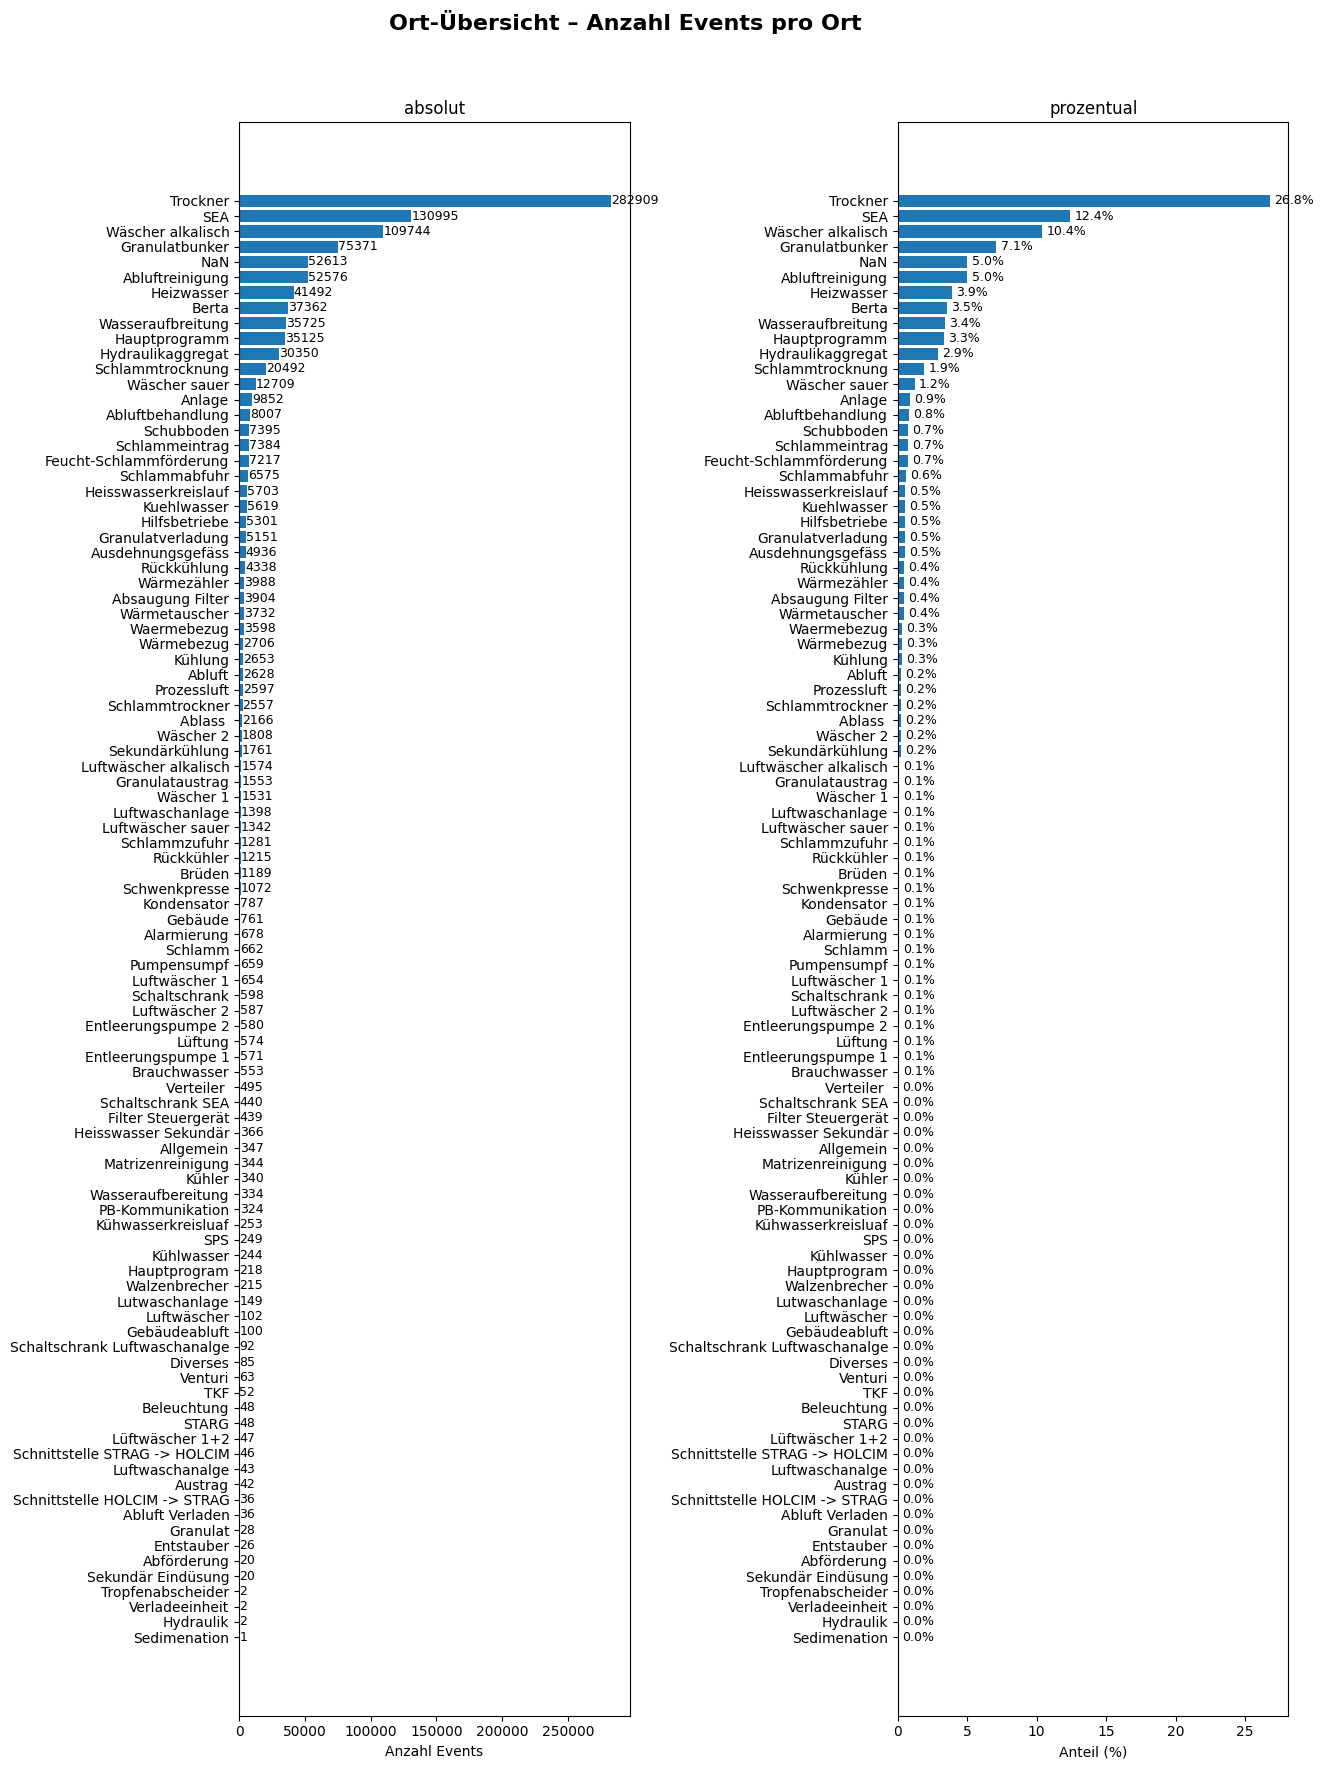

In [146]:
# Einträge verteilt auf Orte
fig, axes = plt.subplots(1, 2, figsize=(14, 18))

# --- Plot 1: Alle Orte ---
ort_counts = df["Ort"].fillna("NaN").value_counts()
bars = axes[0].barh(
    ort_counts.index, ort_counts.values
)
for bar, val in zip(bars, ort_counts.values, strict=False):
    axes[0].text(
        bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, str(val), va="center", fontsize=9
    )
axes[0].set_xlabel("Anzahl Events")
axes[0].set_title("absolut")
axes[0].invert_yaxis()

ort_pct = (ort_counts / ort_counts.sum() * 100).round(1)
bars2 = axes[1].barh(
    ort_pct.index, ort_pct.values
)
for bar, val in zip(bars2, ort_pct.values, strict=False):
    axes[1].text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{val}%",
        va="center",
        fontsize=9,
    )
axes[1].set_xlabel("Anteil (%)")
axes[1].set_title("prozentual")
axes[1].invert_yaxis()

plt.suptitle("Ort-Übersicht – Anzahl Events pro Ort", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0.05, 0, 1, 0.96])
plt.show()

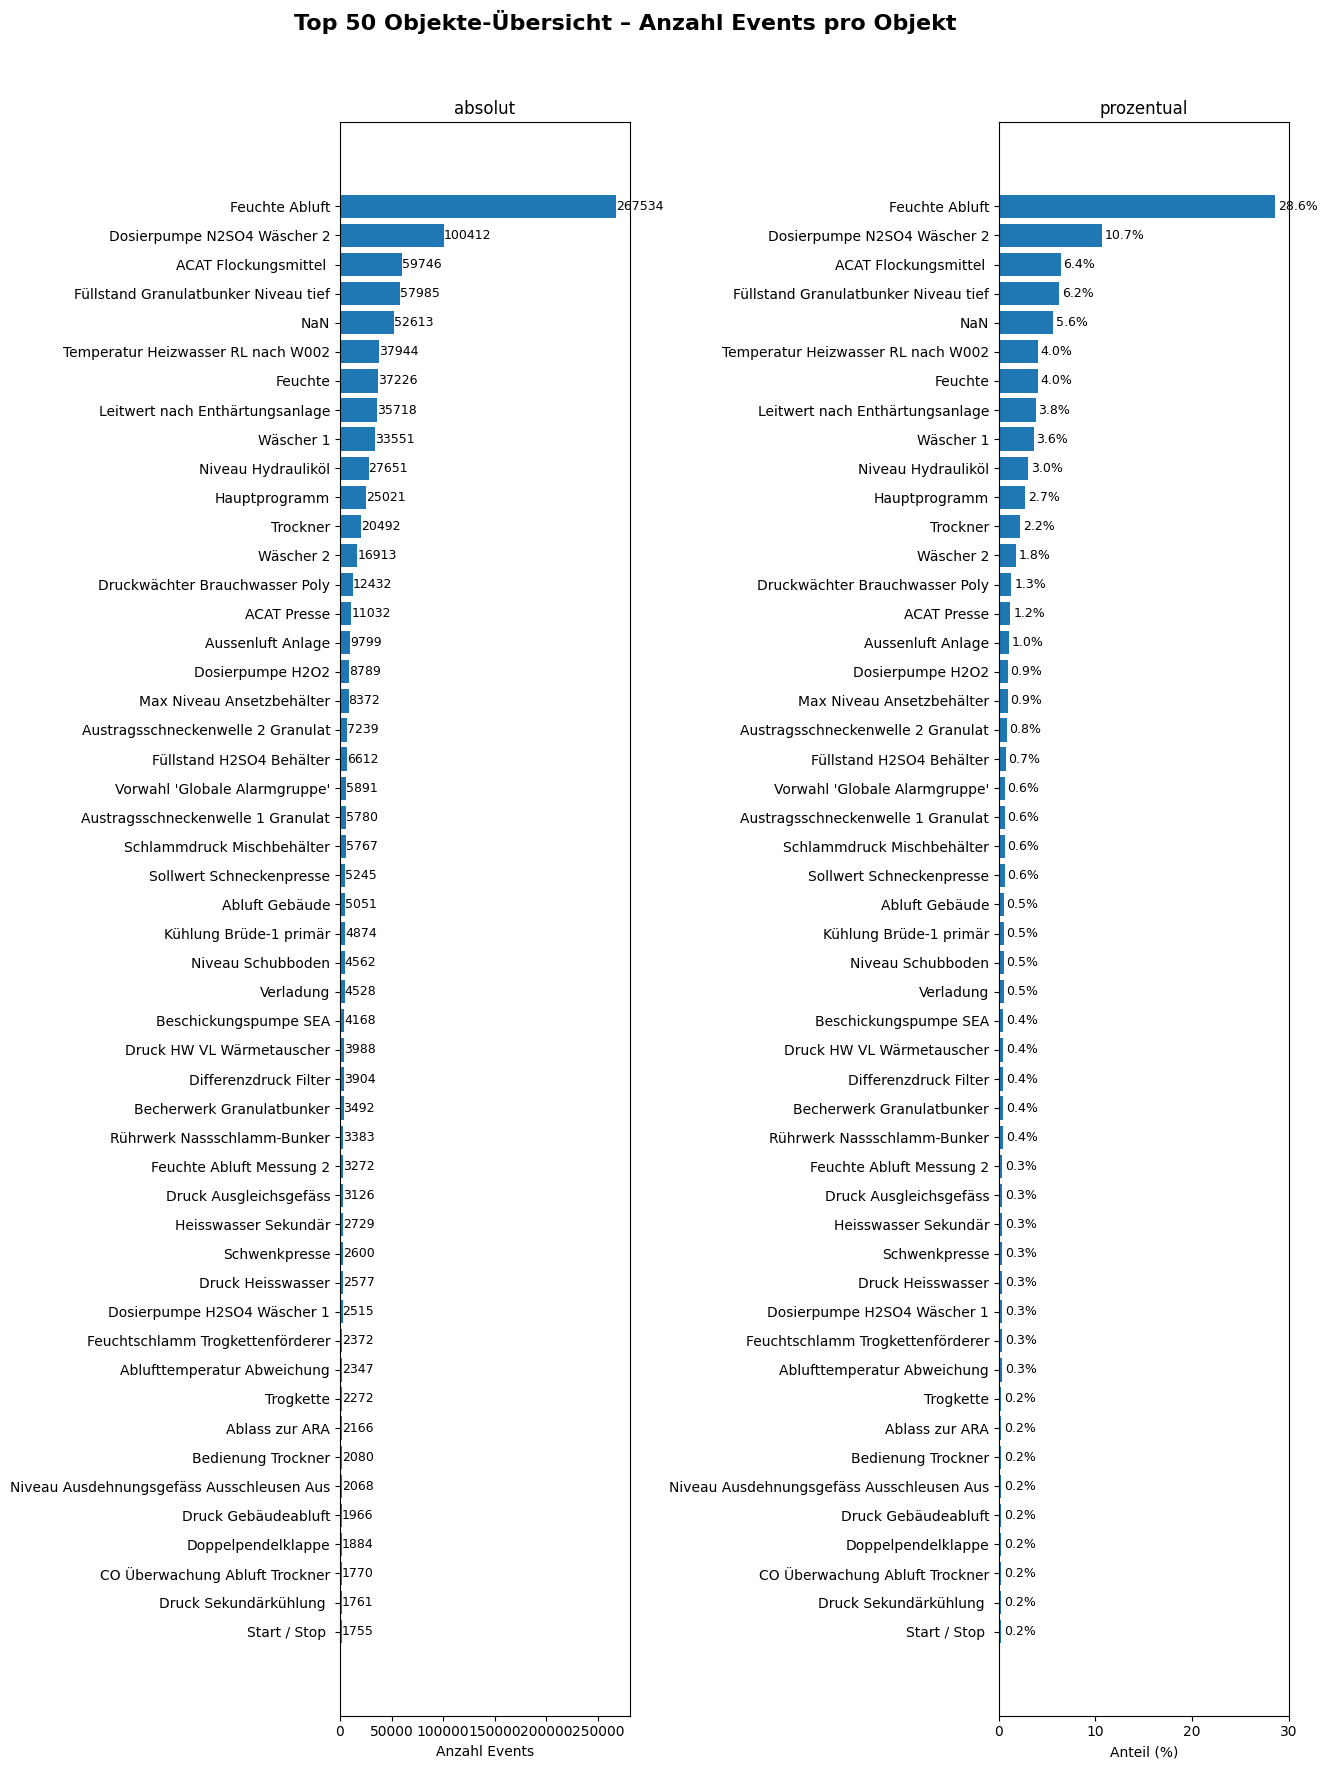

In [147]:
# Einträge der Top 50 Orte
fig, axes = plt.subplots(1, 2, figsize=(14, 18))

# --- Plot 1: Alle Orte ---
objekt_counts = df["Objekt"].fillna("NaN").value_counts().head(50)
bars = axes[0].barh(
    objekt_counts.index, objekt_counts.values
)
for bar, val in zip(bars, objekt_counts.values, strict=False):
    axes[0].text(
        bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, str(val), va="center", fontsize=9
    )
axes[0].set_xlabel("Anzahl Events")
axes[0].set_title("absolut")
axes[0].invert_yaxis()

objekt_pct = (objekt_counts / objekt_counts.sum() * 100).round(1)
bars2 = axes[1].barh(
    objekt_pct.index, objekt_pct.values
)
for bar, val in zip(bars2, objekt_pct.values, strict=False):
    axes[1].text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{val}%",
        va="center",
        fontsize=9,
    )
axes[1].set_xlabel("Anteil (%)")
axes[1].set_title("prozentual")
axes[1].invert_yaxis()

plt.suptitle("Top 50 Objekte-Übersicht – Anzahl Events pro Objekt", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0.05, 0, 1, 0.96])
plt.show()

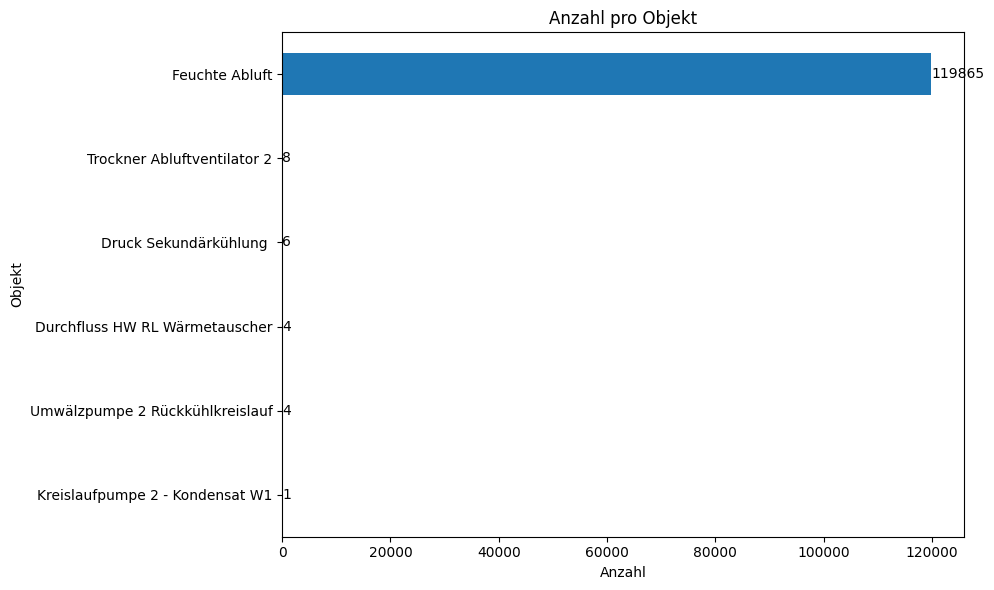

In [148]:
# Betroffene Objekte am 2016-03-04
df_2016_03_04 = df[df["Tag"].astype(str) == "2016-03-04"]
count_2016_03_04 = df_2016_03_04["Objekt"].value_counts()

ax = count_2016_03_04.plot(kind="barh", figsize=(10, 6))

for bar in ax.patches:
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        str(int(bar.get_width())),
        va="center"
    )

plt.xlabel("Anzahl")
plt.ylabel("Objekt")
plt.title("Anzahl pro Objekt")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

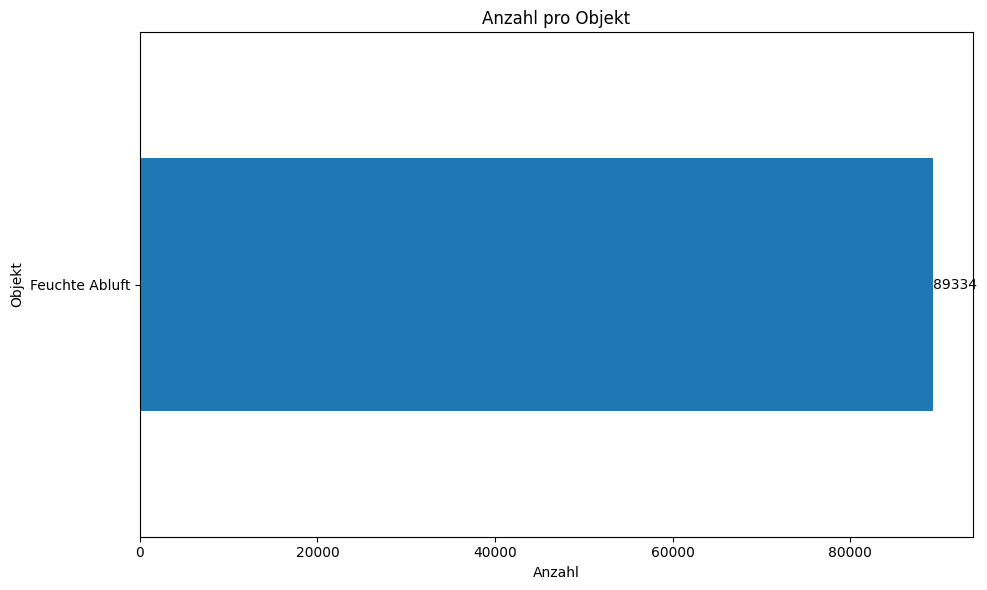

In [149]:
# Betroffene Objekte am 2016-03-05
df_2016_03_05 = df[df["Tag"].astype(str) == "2016-03-05"]
count_2016_03_05 = df_2016_03_05["Objekt"].value_counts()

ax = count_2016_03_05.plot(kind="barh", figsize=(10, 6))

for bar in ax.patches:
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        str(int(bar.get_width())),
        va="center"
    )

plt.xlabel("Anzahl")
plt.ylabel("Objekt")
plt.title("Anzahl pro Objekt")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

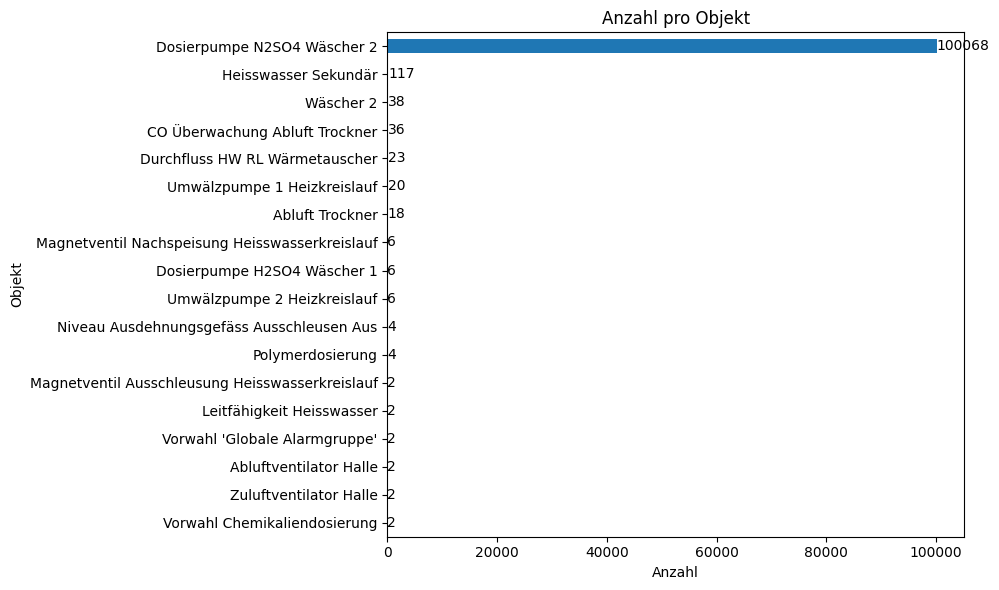

In [150]:
# Betroffene Objekte am 2021-12-06
df_2021_12_06 = df[df["Tag"].astype(str) == "2021-12-06"]
count_2021_12_06 = df_2021_12_06["Objekt"].value_counts()

ax = count_2021_12_06.plot(kind="barh", figsize=(10, 6))

for bar in ax.patches:
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        str(int(bar.get_width())),
        va="center"
    )

plt.xlabel("Anzahl")
plt.ylabel("Objekt")
plt.title("Anzahl pro Objekt")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Tage mit den meisten Eintraegen entfernen


## Cleaning


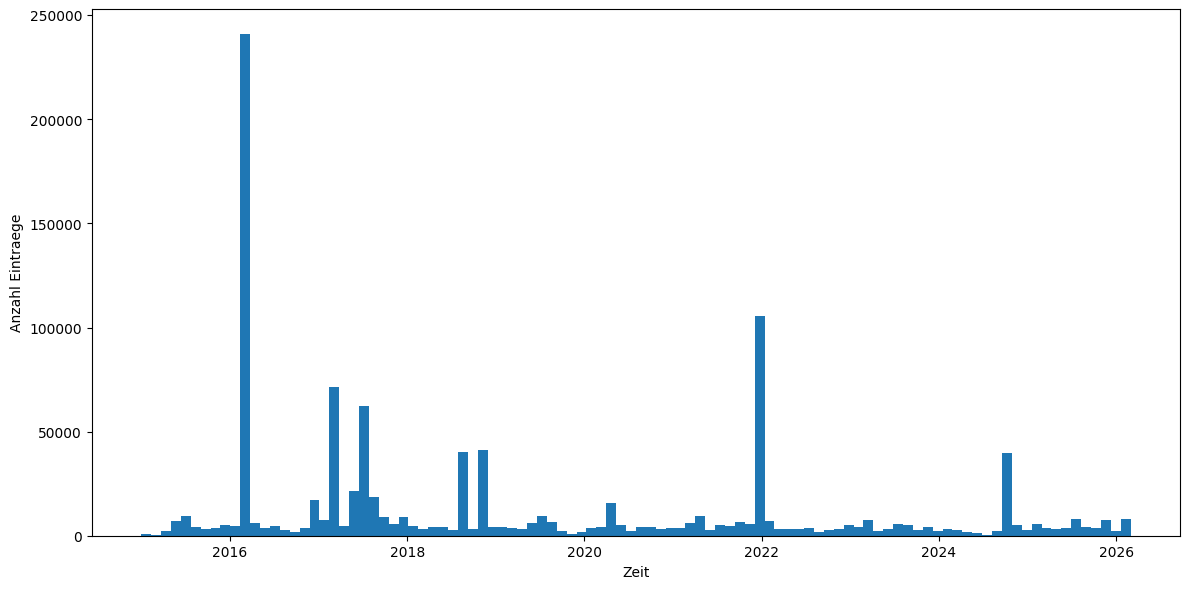

In [151]:
# Hohe anzahl Meldungen an einem Tag (Histogramm fuer Uebersicht)

df_raw = df.copy()

plt.figure(figsize=(12, 6))
plt.hist(df_raw["Datum"].dropna(), bins=100)
plt.xlabel("Zeit")
plt.ylabel("Anzahl Eintraege")
plt.tight_layout()
plt.show()

In [152]:
# Tage mit meisten Meldungen
outlier_day = df_raw["Tag"].value_counts().head(10)
outlier_list = outlier_day.index
outlier_day

Tag
2016-03-04    119895
2021-12-06    100391
2016-03-05     89339
2017-07-16     43746
2018-10-26     34577
2017-02-20     24287
2016-03-03     20008
2024-10-14     18547
2024-10-13     17195
2018-07-29     16686
Name: count, dtype: int64

In [153]:
df = df_raw[~df_raw["Tag"].isin(outlier_list)].copy()
df

,Datum,Prio,Msr,Ort,Objekt,Meldung,Zustand,Benutzer,evtID,evtTyp,Stunde,Wochentag,Wochentag_Nr,Tag,Woche,Monat
0,2015-01-01 19:26:39.200,0.0,PARA-1810,Schlammeintrag,Pauseenzeit Hinten Schubboden fix,NaN,NaN,Balz,321990,Sollwert-Vorgaben,19,Thursday,3,2015-01-01,1,2015-01
1,2015-01-01 19:26:32.960,0.0,PARA-1809,Schlammeintrag,Pausenzeit Vorne Schubboden fix,NaN,NaN,Balz,321989,Sollwert-Vorgaben,19,Thursday,3,2015-01-01,1,2015-01
2,2015-01-01 19:24:14.572,0.0,PARA-1810,Schlammeintrag,Pauseenzeit Hinten Schubboden fix,NaN,NaN,Balz,321988,Sollwert-Vorgaben,19,Thursday,3,2015-01-01,1,2015-01
3,2015-01-01 19:24:08.769,0.0,PARA-1809,Schlammeintrag,Pausenzeit Vorne Schubboden fix,NaN,NaN,Balz,321987,Sollwert-Vorgaben,19,Thursday,3,2015-01-01,1,2015-01
4,2015-01-01 14:13:34.565,0.0,PARA-1810,Schlammeintrag,Pauseenzeit Hinten Schubboden fix,NaN,NaN,Balz,321956,Sollwert-Vorgaben,14,Thursday,3,2015-01-01,1,2015-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1054551,2026-02-28 00:32:32.840,0.0,MISA-175A,Granulatbunker,Produktionsfeuchte,Unterer Grenzwert Warnung,Kommt,NaN,1017948,Störmeldungen,0,Saturday,5,2026-02-28,9,2026-02
1054552,2026-02-28 00:31:02.070,0.0,MISA-175A,Granulatbunker,Produktionsfeuchte,Unterer Grenzwert Warnung,Geht,NaN,1017947,Störmeldungen,0,Saturday,5,2026-02-28,9,2026-02
1054553,2026-02-28 00:22:39.291,0.0,MISA-175A,Granulatbunker,Produktionsfeuchte,Unterer Grenzwert Warnung,Kommt,NaN,1017947,Störmeldungen,0,Saturday,5,2026-02-28,9,2026-02
1054554,2026-02-28 00:15:44.270,0.0,MISA-175A,Granulatbunker,Produktionsfeuchte,Unterer Grenzwert Warnung,Geht,NaN,1017946,Störmeldungen,0,Saturday,5,2026-02-28,9,2026-02


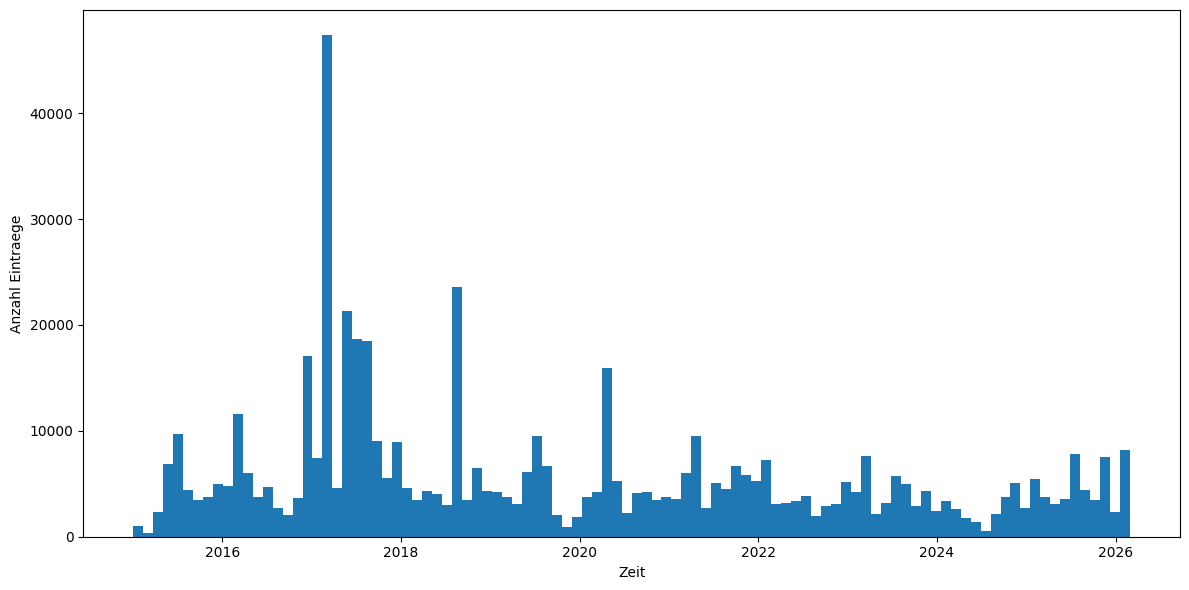

In [154]:
plt.figure(figsize=(12, 6))
plt.hist(df["Datum"].dropna(), bins=100)
plt.xlabel("Zeit")
plt.ylabel("Anzahl Eintraege")
plt.tight_layout()
plt.show()

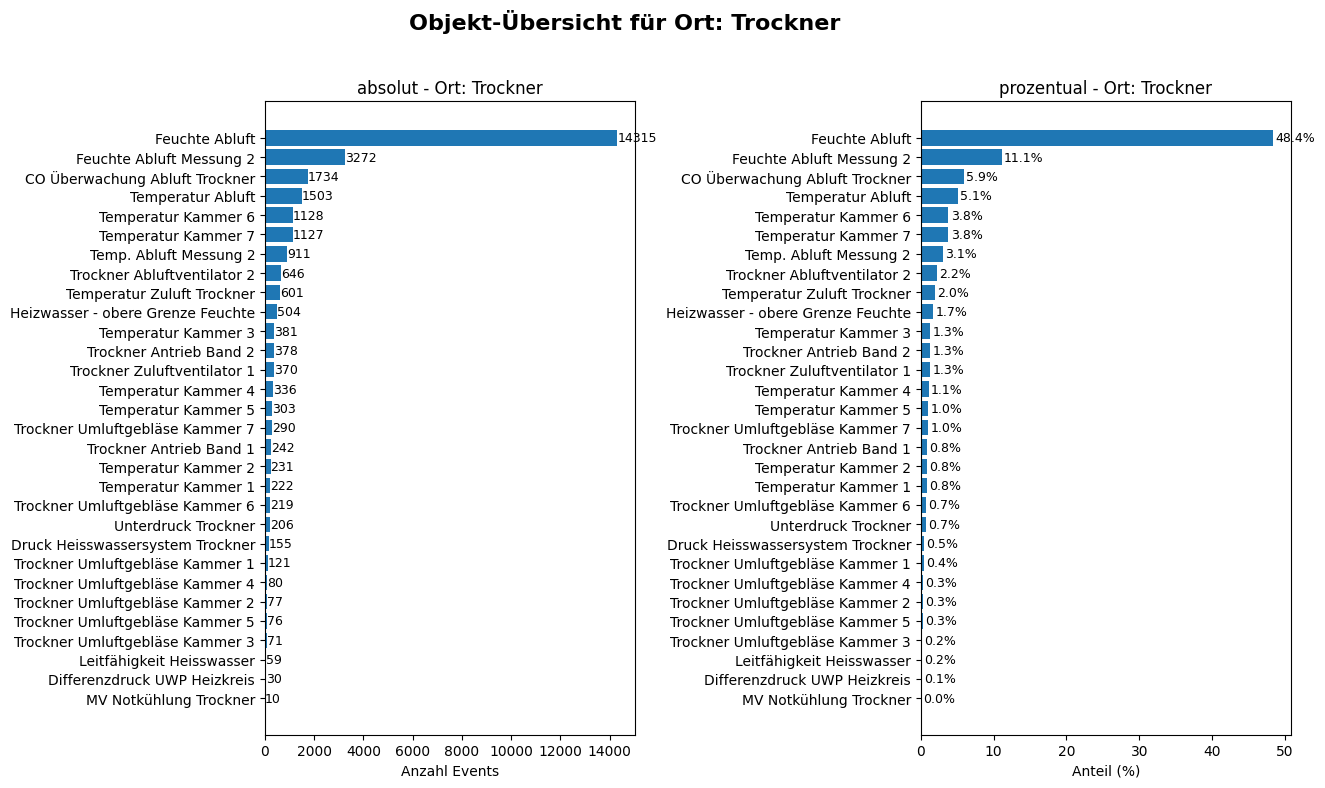

In [155]:
# Pro Ort können die Objekte betrachtet werden
selected_ort = "Trockner"

df_ort = df[df["Ort"].fillna("NaN") == selected_ort]

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# --- Plot 1: Alle Objekte ---
objekt_counts = df_ort["Objekt"].fillna("NaN").value_counts()
bars = axes[0].barh(
    objekt_counts.index, objekt_counts.values
)
for bar, val in zip(bars, objekt_counts.values, strict=False):
    axes[0].text(
        bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, str(val), va="center", fontsize=9
    )
axes[0].set_xlabel("Anzahl Events")
axes[0].set_title(f"absolut - Ort: {selected_ort}")
axes[0].invert_yaxis()

objekt_pct = (objekt_counts / objekt_counts.sum() * 100).round(1)
bars2 = axes[1].barh(
    objekt_pct.index, objekt_pct.values
)
for bar, val in zip(bars2, objekt_pct.values, strict=False):
    axes[1].text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{val}%",
        va="center",
        fontsize=9,
    )
axes[1].set_xlabel("Anteil (%)")
axes[1].set_title(f"prozentual - Ort: {selected_ort}")
axes[1].invert_yaxis()

plt.suptitle(f"Objekt-Übersicht für Ort: {selected_ort}", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0.05, 0, 1, 0.96])
plt.show()

In [156]:
# Meldungen zum Objekt
df_feuchte_abluft = df[df["Objekt"] == "Feuchte Abluft"]
df_feuchte_abluft["Meldung"].value_counts()

Meldung
Drahtbruch - Messbereich um 10% unterschritten    11533
Oberer Grenzwert Warnung                           1851
Oberer Grenzwert Alarm                               88
Überlauf - Messbereich um 10% überschritten          84
Name: count, dtype: int64

Es  gibt 3 arten von Objekten (bezogen auf die Nächste Tabelle) 
- 100% Störmeldung
- 100% Sollwertvorgabe
- mischung aus Aggregate-Vorwahlen und Nicht bereit
natürlich hat es meistens auch noch andere Meldungstypen drin, aber dies sticht heraus.

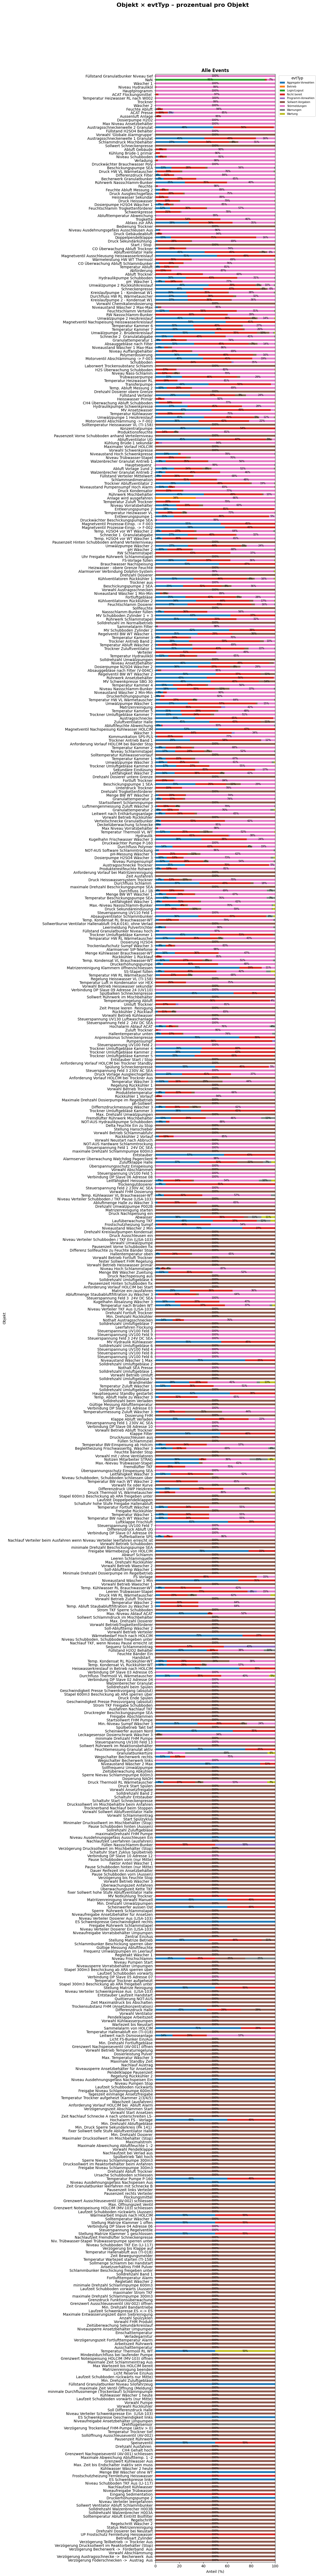

In [157]:
# Verteilung eventTyp pro Objekt
cmap_evt = plt.cm.tab10
all_evt_types = sorted(df["evtTyp"].dropna().unique())
evt_colors = {col: cmap_evt(i) for i, col in enumerate(all_evt_types)}

ct = pd.crosstab(df["Objekt"].fillna("NaN"), df["evtTyp"].fillna("NaN"))
ct = ct.reindex(columns=[c for c in all_evt_types if c in ct.columns], fill_value=0)
ort_order = ct.sum(axis=1).sort_values(ascending=True).index

ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(1, 1, figsize=(14, 100))

ct_norm.loc[ort_order].plot(
    kind="barh", stacked=True, ax=ax, color=[evt_colors[c] for c in ct.columns]
)

for container in ax.containers:
    lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
    ax.bar_label(container, labels=lbl, label_type="center", fontsize=7)

ax.set_xlabel("Anteil (%)")
ax.set_title("Alle Events", fontsize=12, fontweight="bold")
ax.legend(title="evtTyp", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)

plt.suptitle("Objekt × evtTyp – prozentual pro Objekt", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 0.88, 0.96])
plt.show()

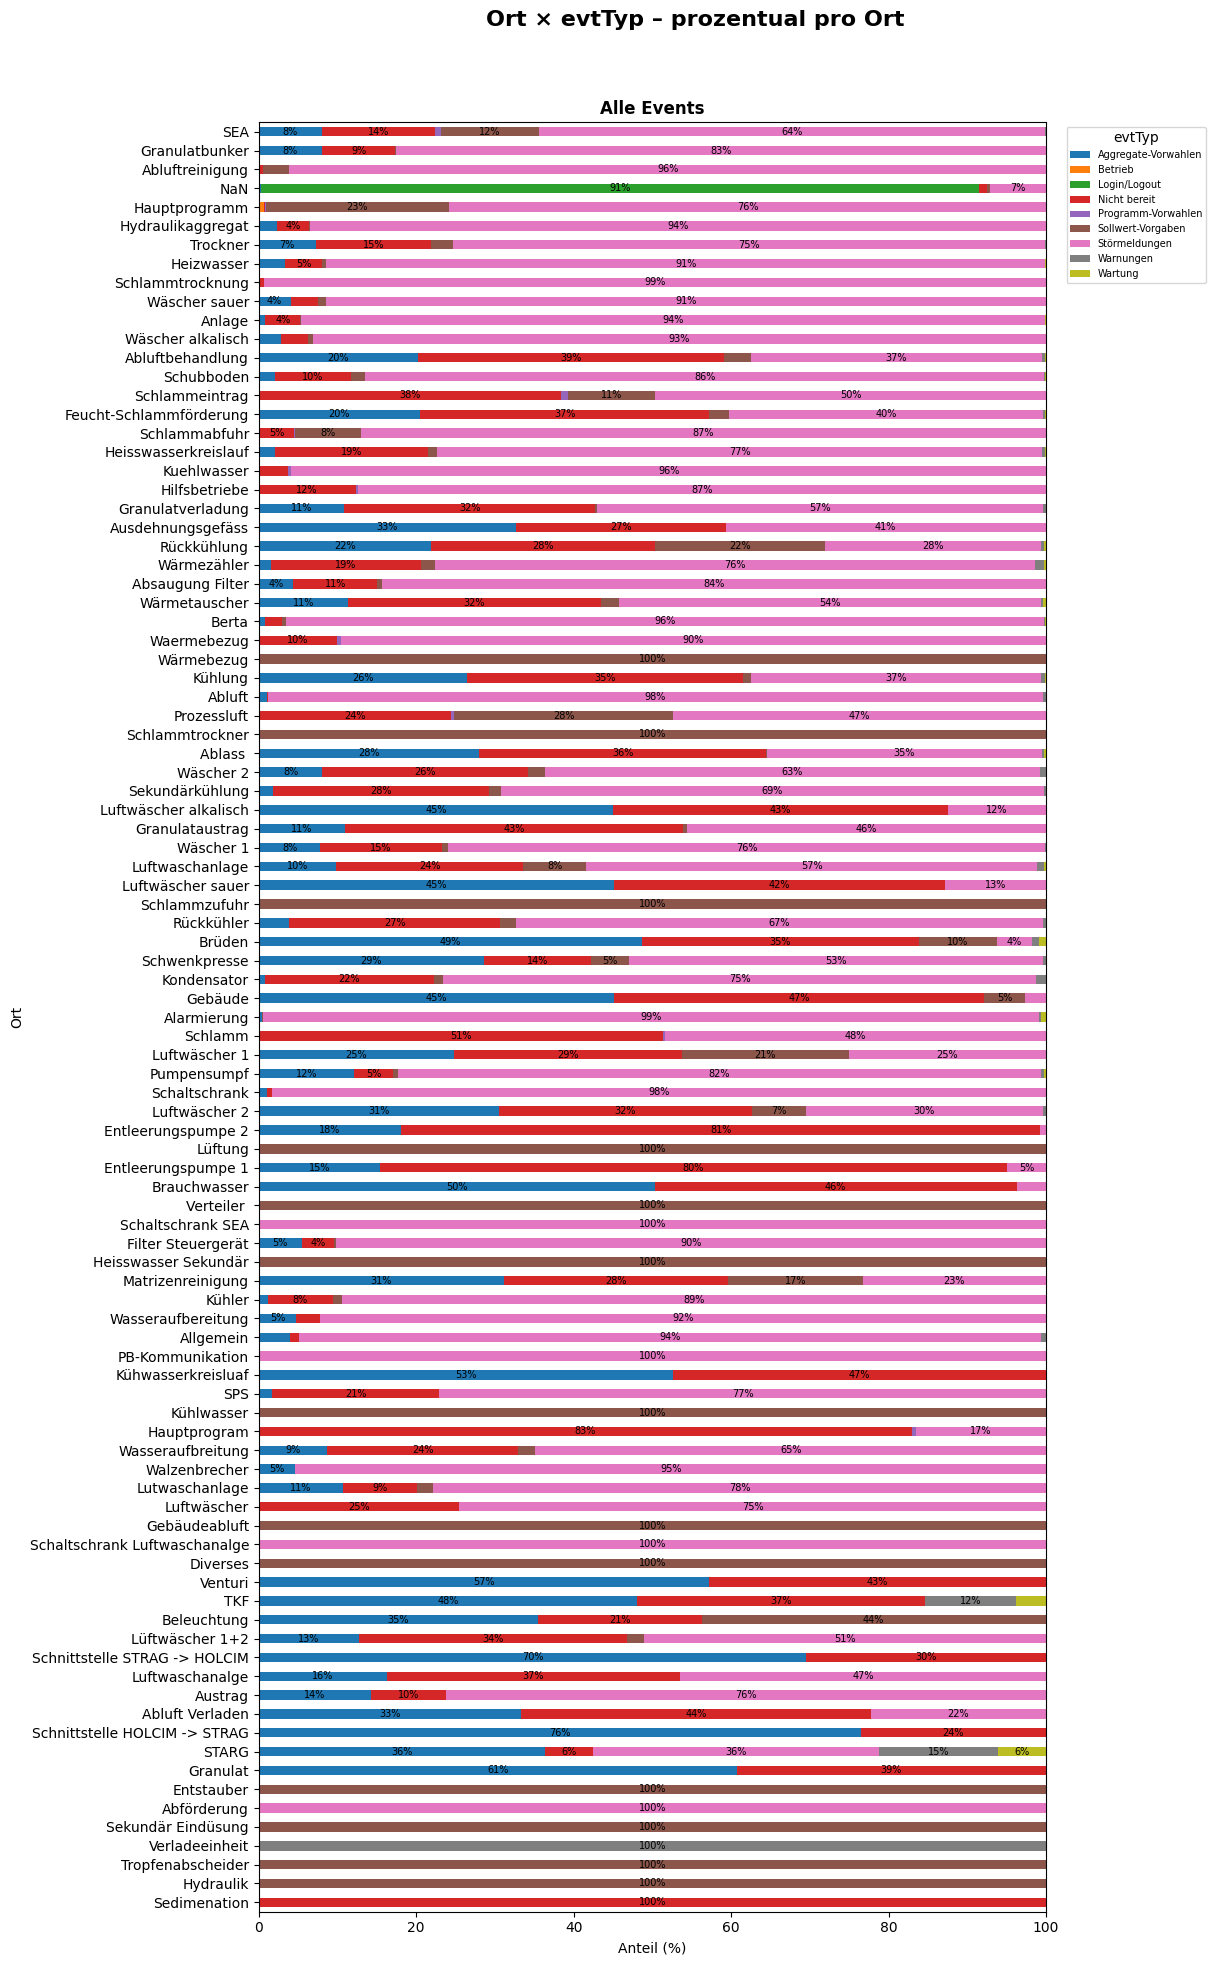

In [107]:
# Verteilung eventTyp pro Ort
cmap_evt = plt.cm.tab10
all_evt_types = sorted(df["evtTyp"].dropna().unique())
evt_colors = {col: cmap_evt(i) for i, col in enumerate(all_evt_types)}

ct = pd.crosstab(df["Ort"].fillna("NaN"), df["evtTyp"].fillna("NaN"))
ct = ct.reindex(columns=[c for c in all_evt_types if c in ct.columns], fill_value=0)
ort_order = ct.sum(axis=1).sort_values(ascending=True).index

ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(1, 1, figsize=(14, 20))

ct_norm.loc[ort_order].plot(
    kind="barh", stacked=True, ax=ax, color=[evt_colors[c] for c in ct.columns]
)

for container in ax.containers:
    lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
    ax.bar_label(container, labels=lbl, label_type="center", fontsize=7)

ax.set_xlabel("Anteil (%)")
ax.set_title("Alle Events", fontsize=12, fontweight="bold")
ax.legend(title="evtTyp", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)

plt.suptitle("Ort × evtTyp – prozentual pro Ort", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 0.88, 0.96])
plt.show()

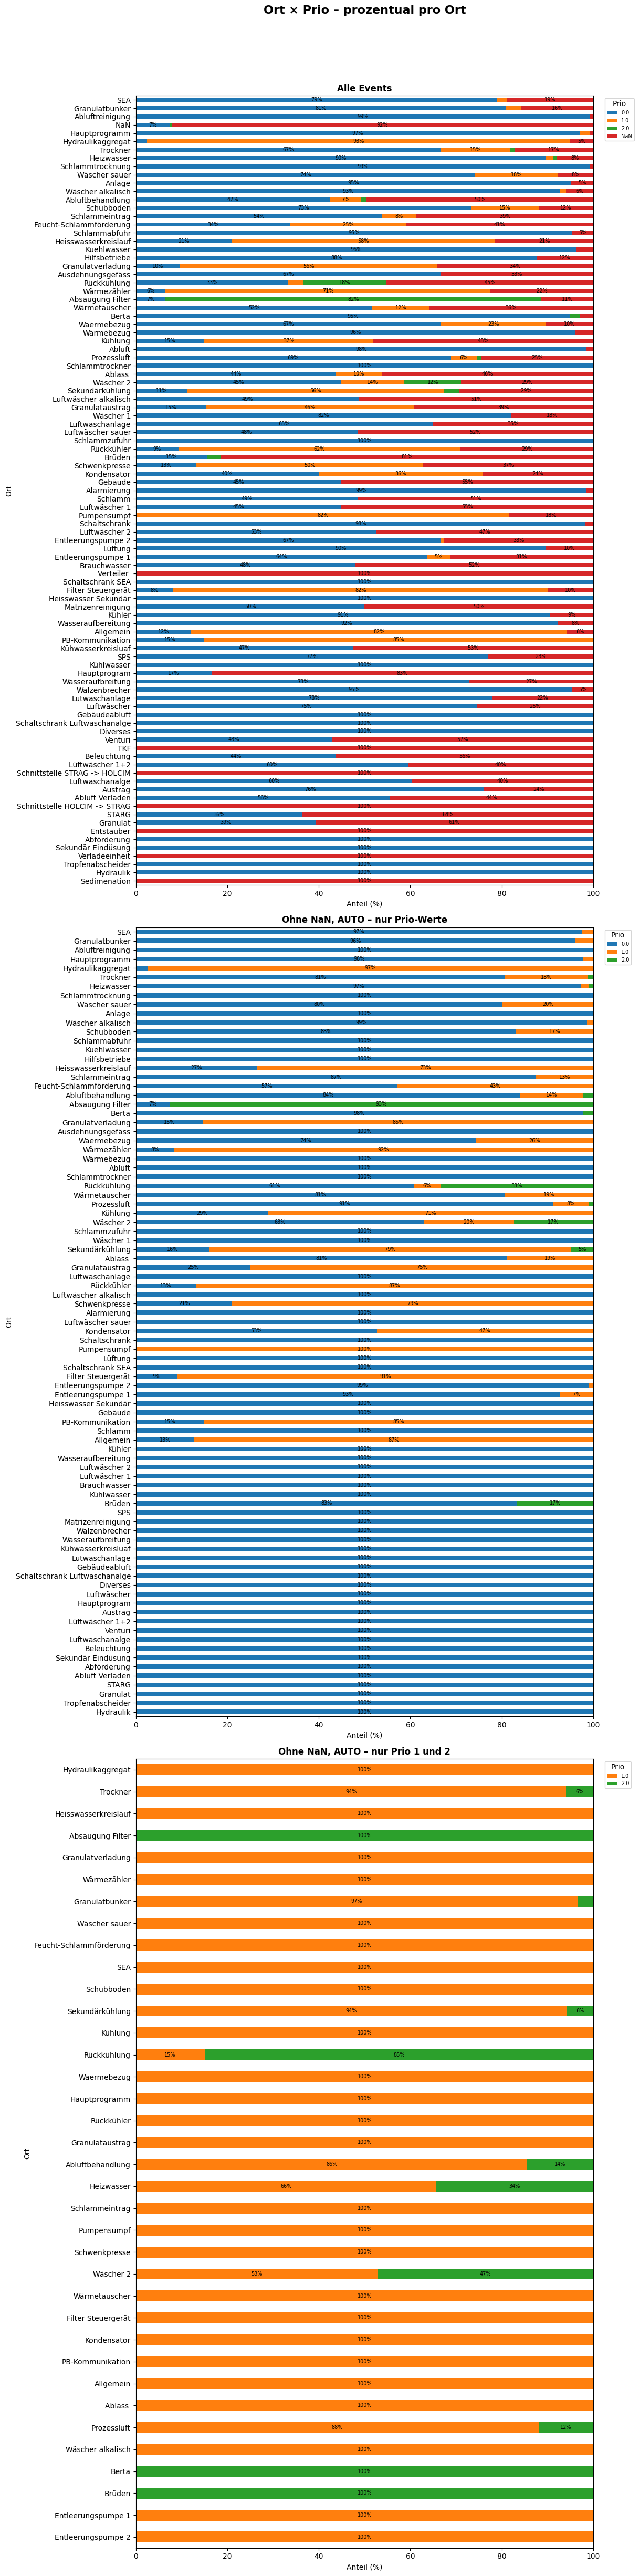

In [108]:
# Verteilung Meldungen nach Prio pro Ort
all_prios = sorted(df["Prio"].dropna().unique())
all_prios_str = [str(p) for p in all_prios] + ["NaN"]
cmap_prio = plt.cm.tab10
prio_colors = {p: cmap_prio(i) for i, p in enumerate(all_prios_str)}

df_no_nan_auto = df[(df["Ort"].notna()) & (~df["Ort"].isin(["AUTO"]))]

fig, axes = plt.subplots(3, 1, figsize=(14, 50))

datasets = [
    (df, "Alle Events", True, None),
    (df_no_nan_auto, "Ohne NaN, AUTO – nur Prio-Werte", False, None),
    (df_no_nan_auto, "Ohne NaN, AUTO – nur Prio 1 und 2", False, ["1.0", "2.0"]),
]

for ax, (data, title, include_nan, only_prios) in zip(axes, datasets, strict=False):
    ct = pd.crosstab(data["Ort"].fillna("NaN"), data["Prio"].fillna("NaN"))
    ct.columns = [str(c) for c in ct.columns]

    if include_nan:
        cols = [c for c in all_prios_str if c in ct.columns]
    else:
        cols = [c for c in all_prios_str if c in ct.columns and c != "NaN"]
        ct = ct[cols]

    if only_prios:
        cols = [c for c in cols if c in only_prios]
        ct = ct[[c for c in cols if c in ct.columns]]

    ct = ct.reindex(columns=cols, fill_value=0)
    # Zeilen ohne Werte entfernen
    ct = ct[ct.sum(axis=1) > 0]
    ort_order = ct.sum(axis=1).sort_values(ascending=True).index

    ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100
    ct_norm.loc[ort_order].plot(
        kind="barh", stacked=True, ax=ax, color=[prio_colors[c] for c in ct.columns]
    )
    for container in ax.containers:
        lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
        ax.bar_label(container, labels=lbl, label_type="center", fontsize=7)
    ax.set_xlabel("Anteil (%)")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.legend(title="Prio", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)

plt.suptitle("Ort × Prio – prozentual pro Ort", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 0.88, 0.96])
plt.show()

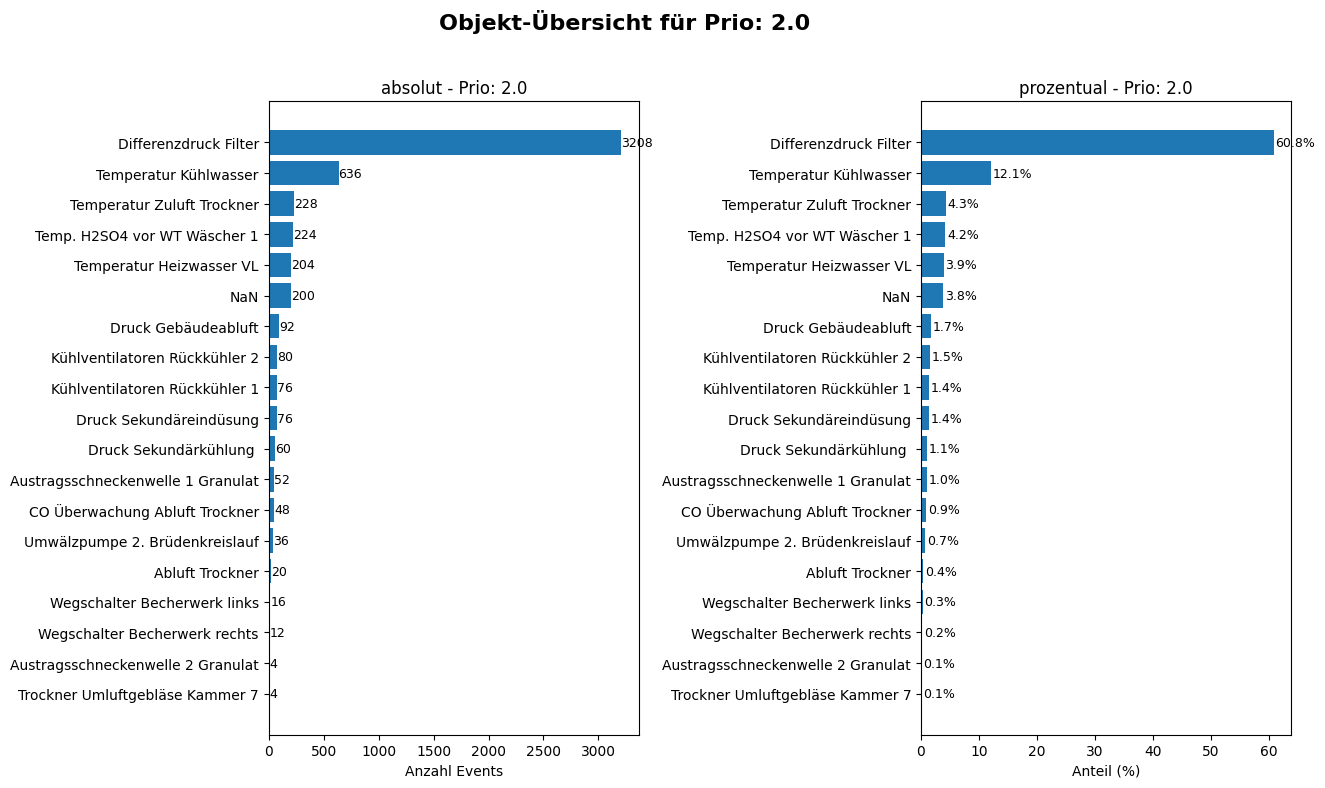

In [109]:
# Verteilung der Einträge pro Objekt mit Prio 1.0
selected_prio = 2.0

df_prio = df[df["Prio"].fillna("NaN") == selected_prio]

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# --- Plot 1: Alle Objekte ---
objekt_counts = df_prio["Objekt"].fillna("NaN").value_counts()
bars = axes[0].barh(
    objekt_counts.index, objekt_counts.values
)
for bar, val in zip(bars, objekt_counts.values, strict=False):
    axes[0].text(
        bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, str(val), va="center", fontsize=9
    )
axes[0].set_xlabel("Anzahl Events")
axes[0].set_title(f"absolut - Prio: {selected_prio}")
axes[0].invert_yaxis()

objekt_pct = (objekt_counts / objekt_counts.sum() * 100).round(1)
bars2 = axes[1].barh(
    objekt_pct.index, objekt_pct.values
)
for bar, val in zip(bars2, objekt_pct.values, strict=False):
    axes[1].text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{val}%",
        va="center",
        fontsize=9,
    )
axes[1].set_xlabel("Anteil (%)")
axes[1].set_title(f"prozentual - Prio: {selected_prio}")
axes[1].invert_yaxis()

plt.suptitle(f"Objekt-Übersicht für Prio: {selected_prio}", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0.05, 0, 1, 0.96])
plt.show()

In [110]:
df_prio2_diff = df_prio[df_prio["Objekt"] == "Differenzdruck Filter"]
df_prio2_diff["Meldung"].value_counts()

Meldung
Oberer Grenzwert Alarm                            2752
Unterer Grenzwert Alarm                            400
Drahtbruch - Messbereich um 10% unterschritten      56
Name: count, dtype: int64

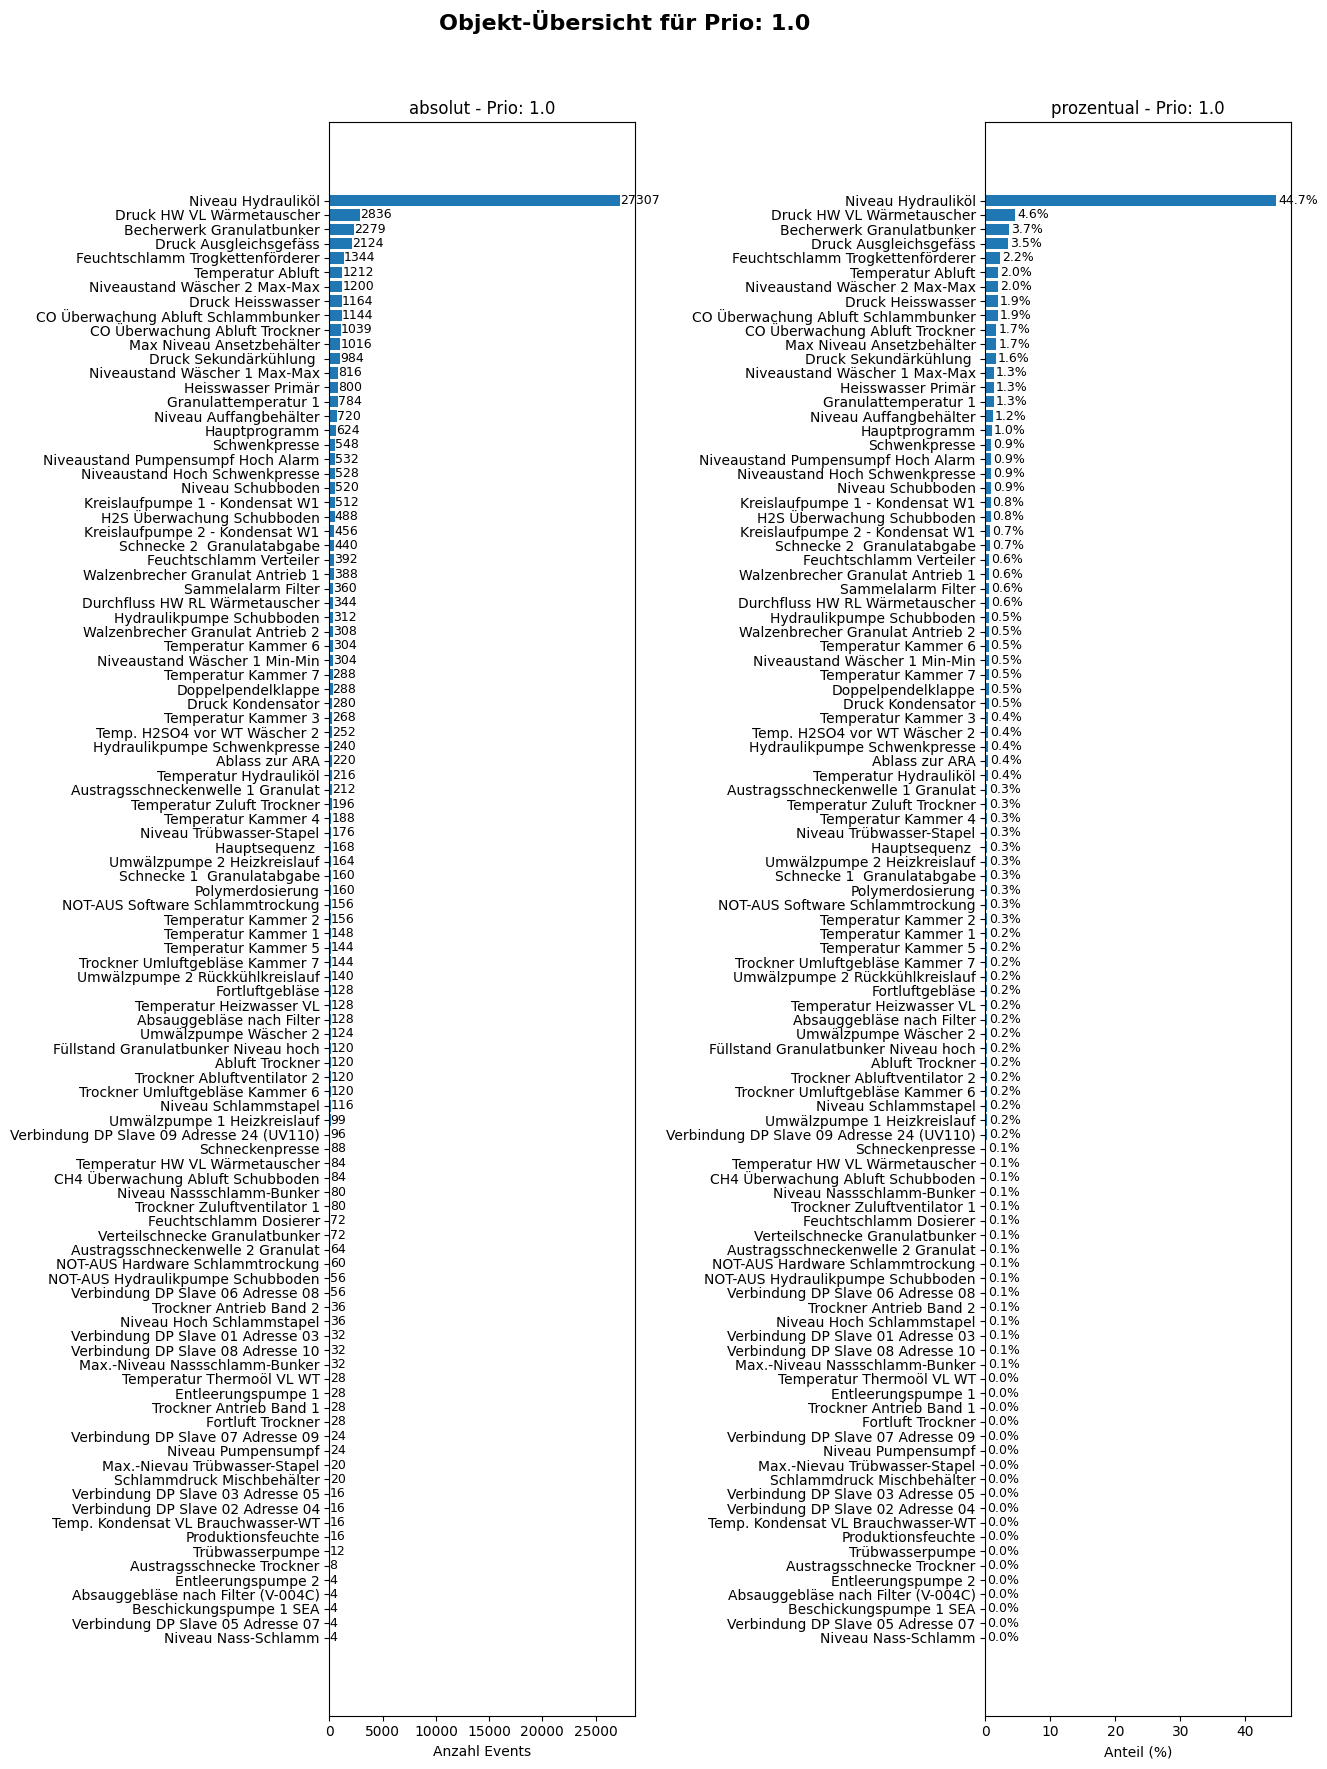

In [111]:
# Verteilung der Einträge pro Objekt mit Prio 1.0
selected_prio = 1.0

df_prio = df[df["Prio"].fillna("NaN") == selected_prio]

fig, axes = plt.subplots(1, 2, figsize=(14, 18))

# --- Plot 1: Alle Objekte ---
objekt_counts = df_prio["Objekt"].fillna("NaN").value_counts()
bars = axes[0].barh(
    objekt_counts.index, objekt_counts.values
)
for bar, val in zip(bars, objekt_counts.values, strict=False):
    axes[0].text(
        bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, str(val), va="center", fontsize=9
    )
axes[0].set_xlabel("Anzahl Events")
axes[0].set_title(f"absolut - Prio: {selected_prio}")
axes[0].invert_yaxis()

objekt_pct = (objekt_counts / objekt_counts.sum() * 100).round(1)
bars2 = axes[1].barh(
    objekt_pct.index, objekt_pct.values
)
for bar, val in zip(bars2, objekt_pct.values, strict=False):
    axes[1].text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{val}%",
        va="center",
        fontsize=9,
    )
axes[1].set_xlabel("Anteil (%)")
axes[1].set_title(f"prozentual - Prio: {selected_prio}")
axes[1].invert_yaxis()

plt.suptitle(f"Objekt-Übersicht für Prio: {selected_prio}", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0.05, 0, 1, 0.96])
plt.show()

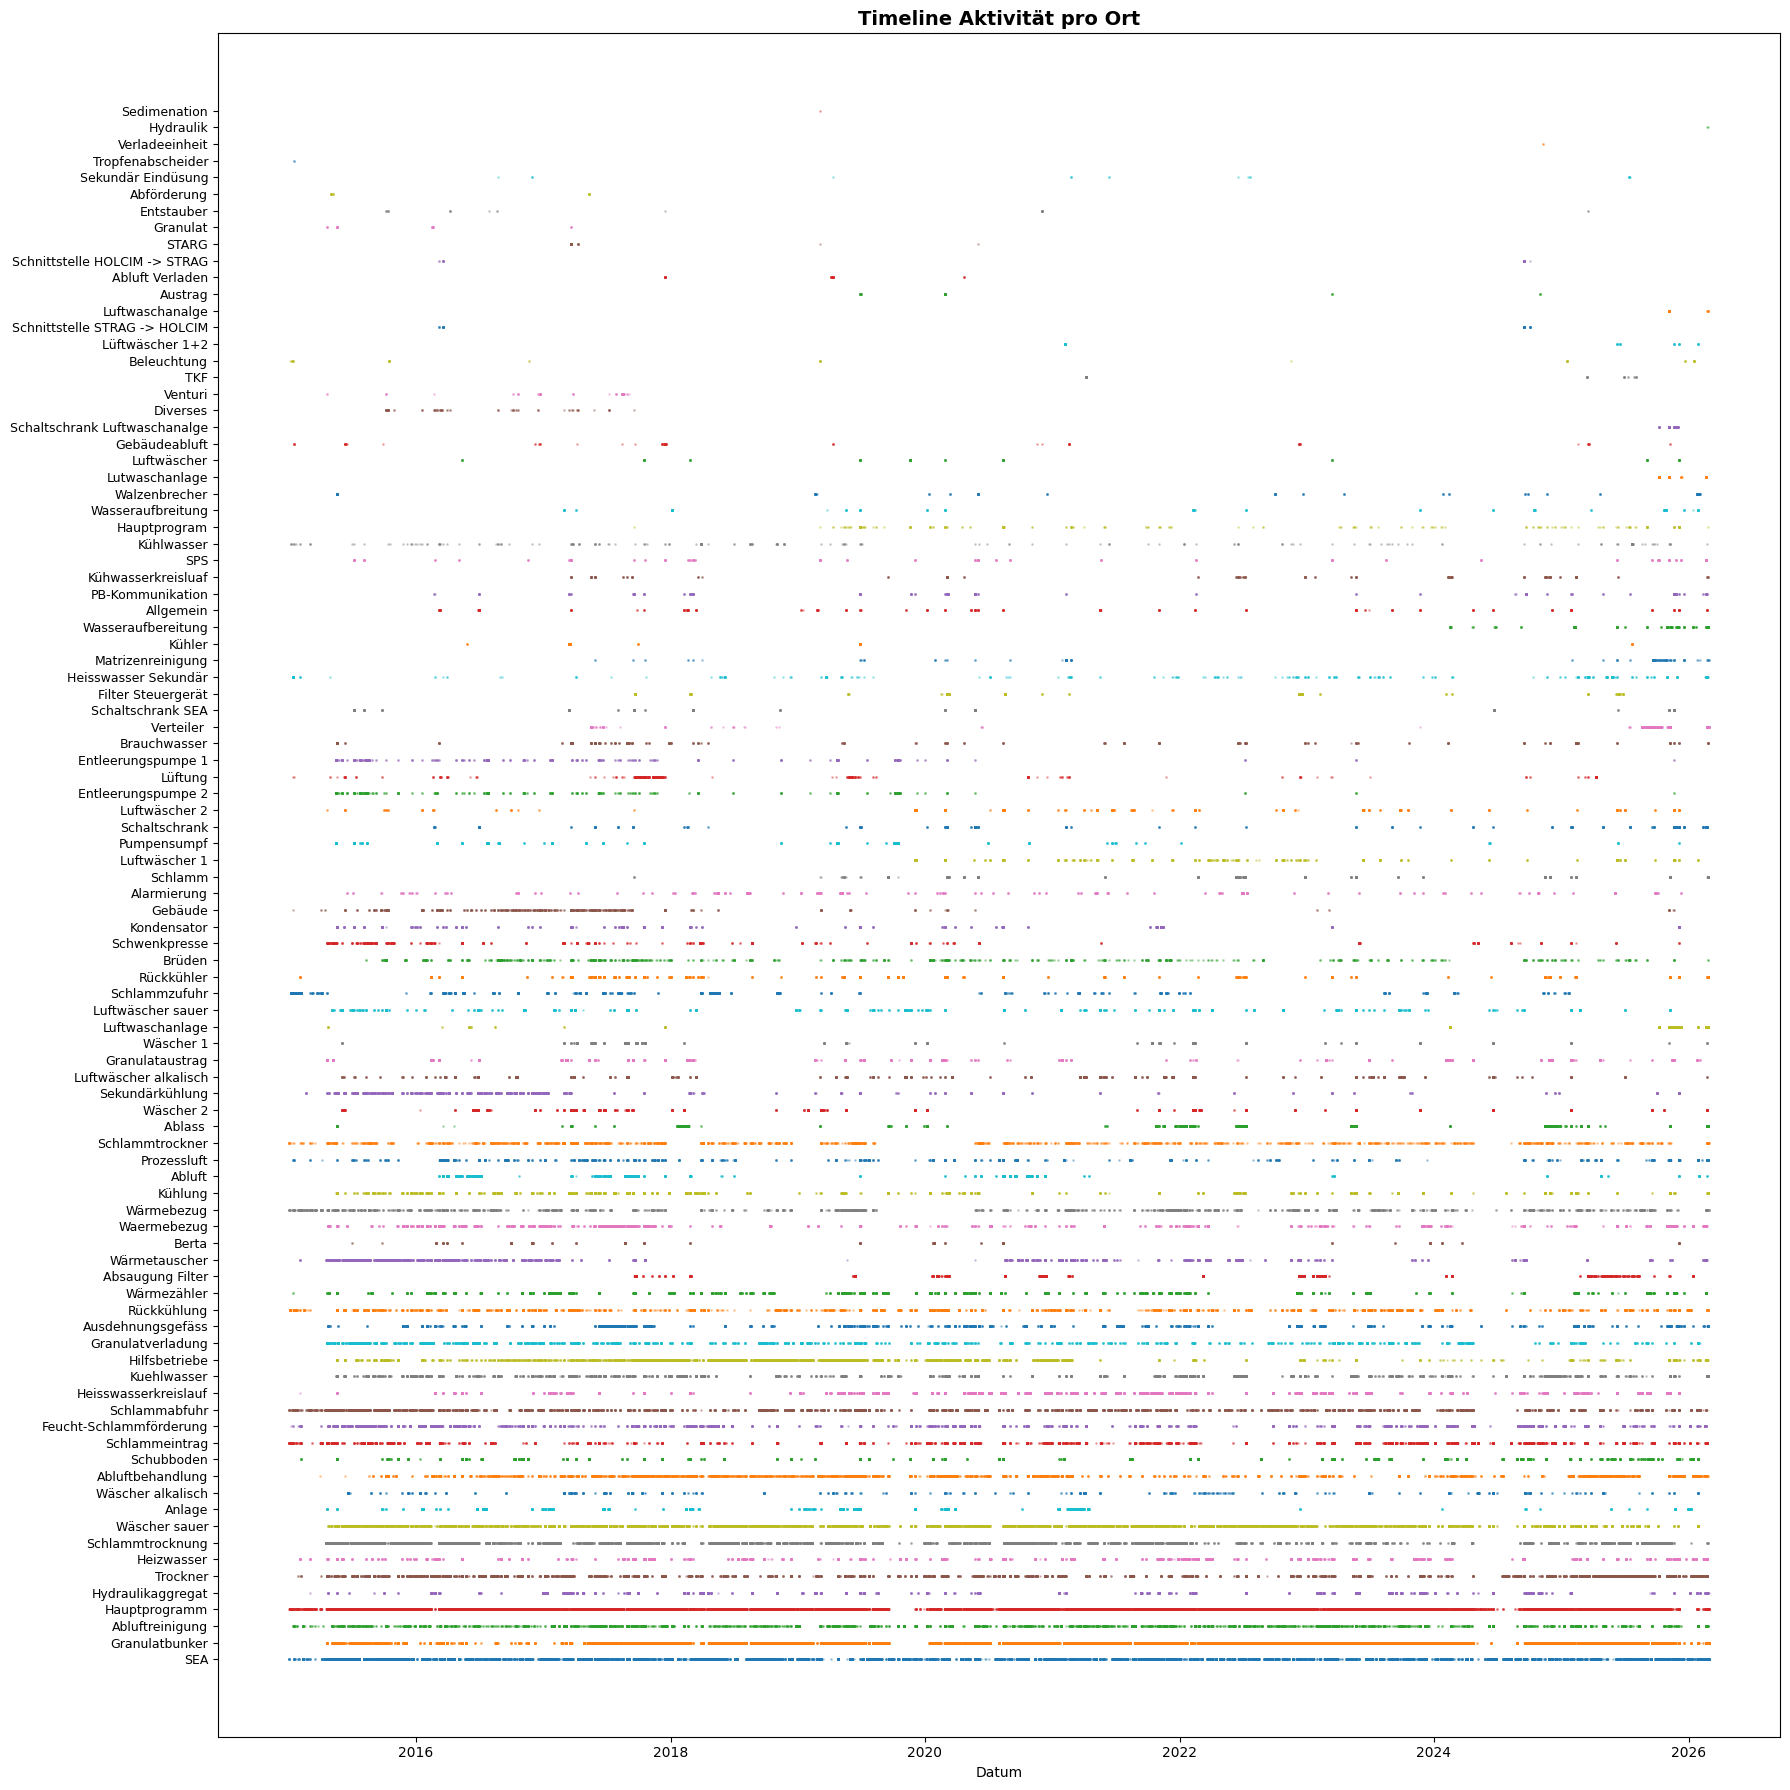

In [112]:
# === Timeline Aktivität pro Ort ===
df_ort = df[(df["Ort"].notna()) & (~df["Ort"].isin(["AUTO"]))]
ort_sorted = df_ort["Ort"].value_counts().index.tolist()

fig, ax = plt.subplots(figsize=(18, 18))
for i, user in enumerate(ort_sorted):
    user_data = df_ort[df_ort["Ort"] == user]
    ax.scatter(user_data["Datum"], [i] * len(user_data), s=1, alpha=0.3, label=user)

ax.set_yticks(range(len(ort_sorted)))
ax.set_yticklabels(ort_sorted, fontsize=9)
ax.set_xlabel("Datum")
ax.set_title("Timeline Aktivität pro Ort", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

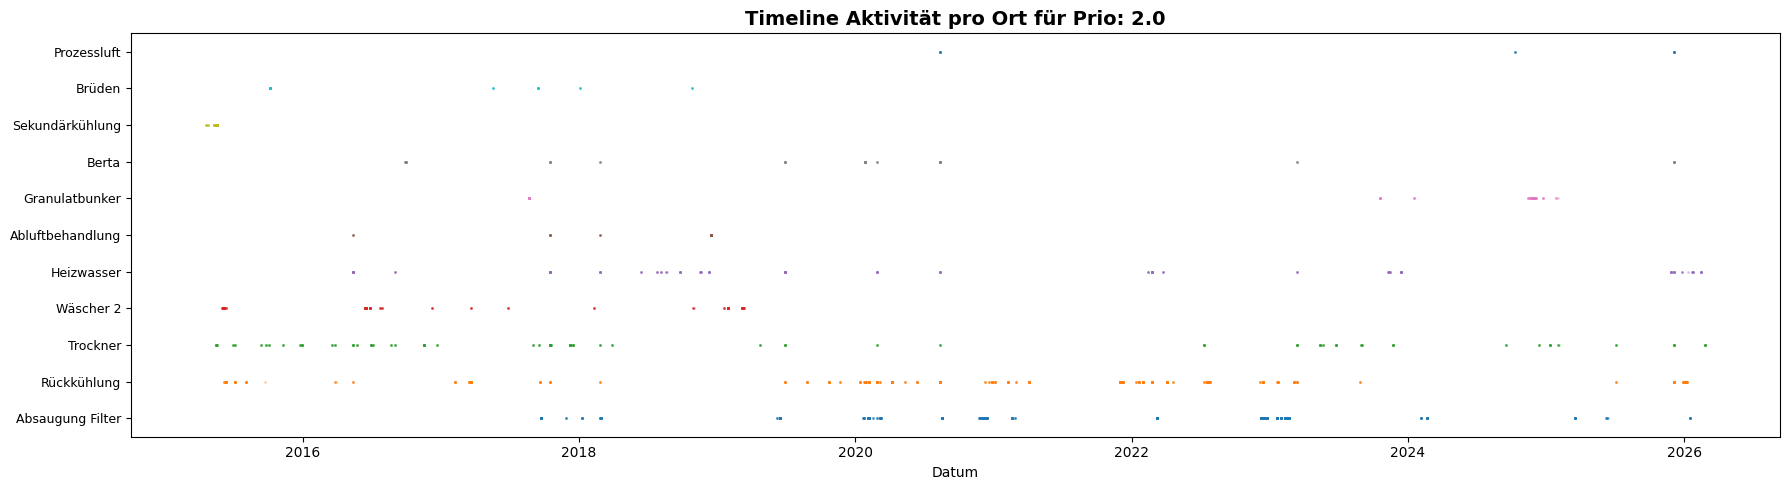

In [113]:
# Timeline der Einträge pro Ort mit Prio 2.0
selected_prio = 2.0

df_prio = df[df["Prio"].fillna("NaN") == selected_prio]

# === 1. Timeline Aktivität pro Ort für Prio ... ===
ort_prio_sorted = df_prio["Ort"].value_counts().index.tolist()

fig, ax = plt.subplots(figsize=(18, 5))
for i, user in enumerate(ort_prio_sorted):
    user_data = df_prio[df_prio["Ort"] == user]
    ax.scatter(user_data["Datum"], [i] * len(user_data), s=1, alpha=0.3, label=user)

ax.set_yticks(range(len(ort_prio_sorted)))
ax.set_yticklabels(ort_prio_sorted, fontsize=9)
ax.set_xlabel("Datum")
ax.set_title(f"Timeline Aktivität pro Ort für Prio: {selected_prio}", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

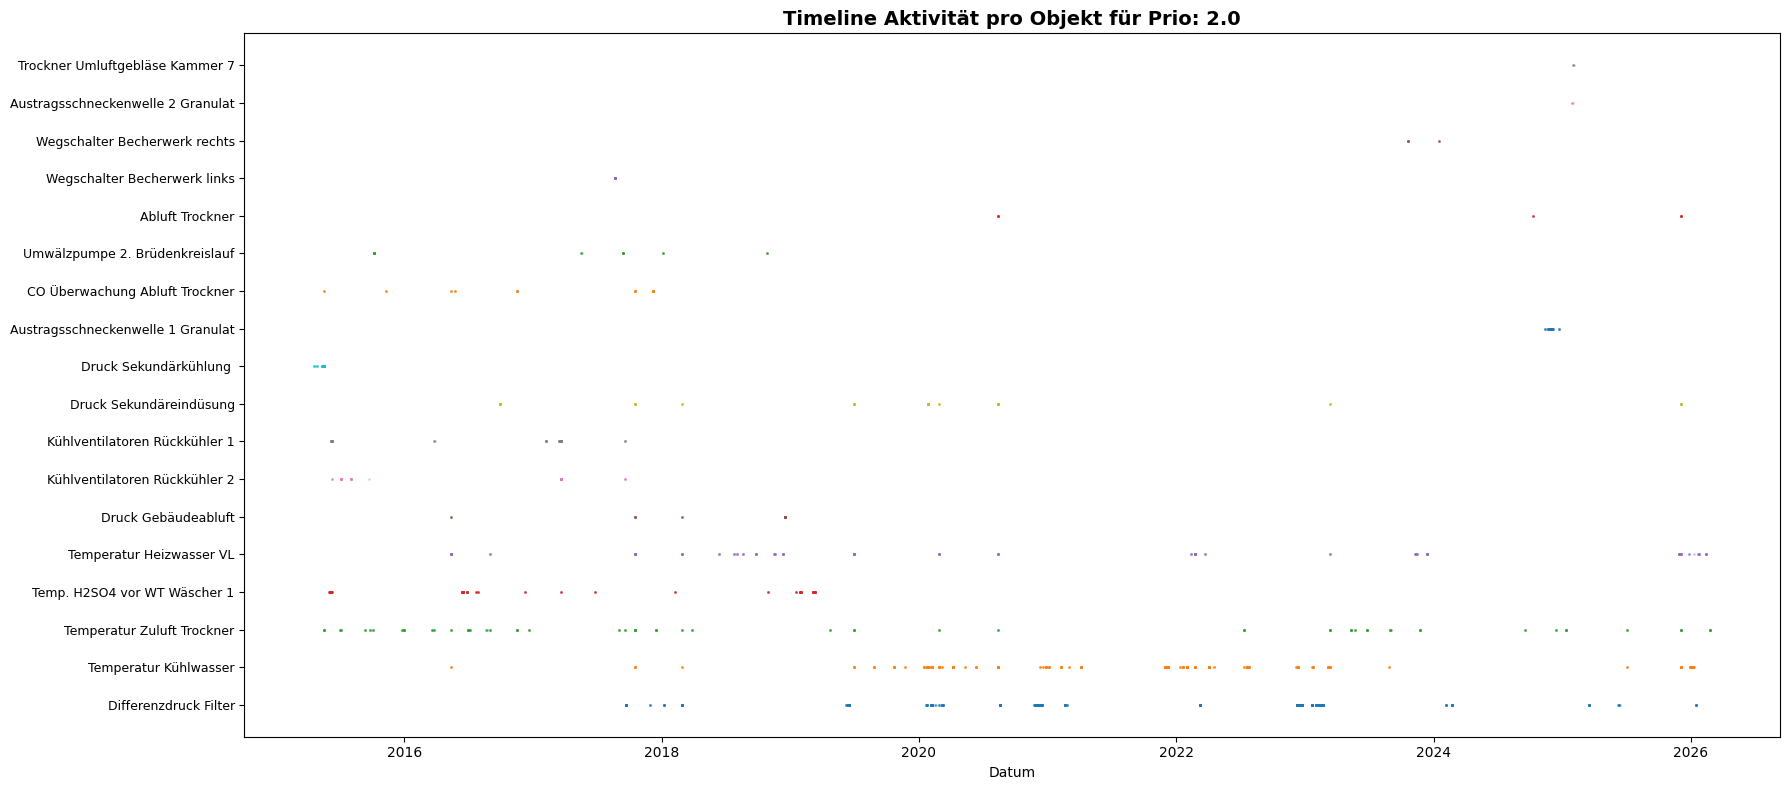

In [114]:
# Timeline der Einträge pro Objekt mit Prio 2.0
selected_prio = 2.0

df_prio = df[df["Prio"].fillna("NaN") == selected_prio]

# ===  Timeline Aktivität pro Objekt für Prio... ===
benutzer_sorted = df_prio["Objekt"].value_counts().index.tolist()

fig, ax = plt.subplots(figsize=(18, 8))
for i, user in enumerate(benutzer_sorted):
    user_data = df_prio[df_prio["Objekt"] == user]
    ax.scatter(user_data["Datum"], [i] * len(user_data), s=1, alpha=0.3, label=user)

ax.set_yticks(range(len(benutzer_sorted)))
ax.set_yticklabels(benutzer_sorted, fontsize=9)
ax.set_xlabel("Datum")
ax.set_title(f"Timeline Aktivität pro Objekt für Prio: {selected_prio}", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

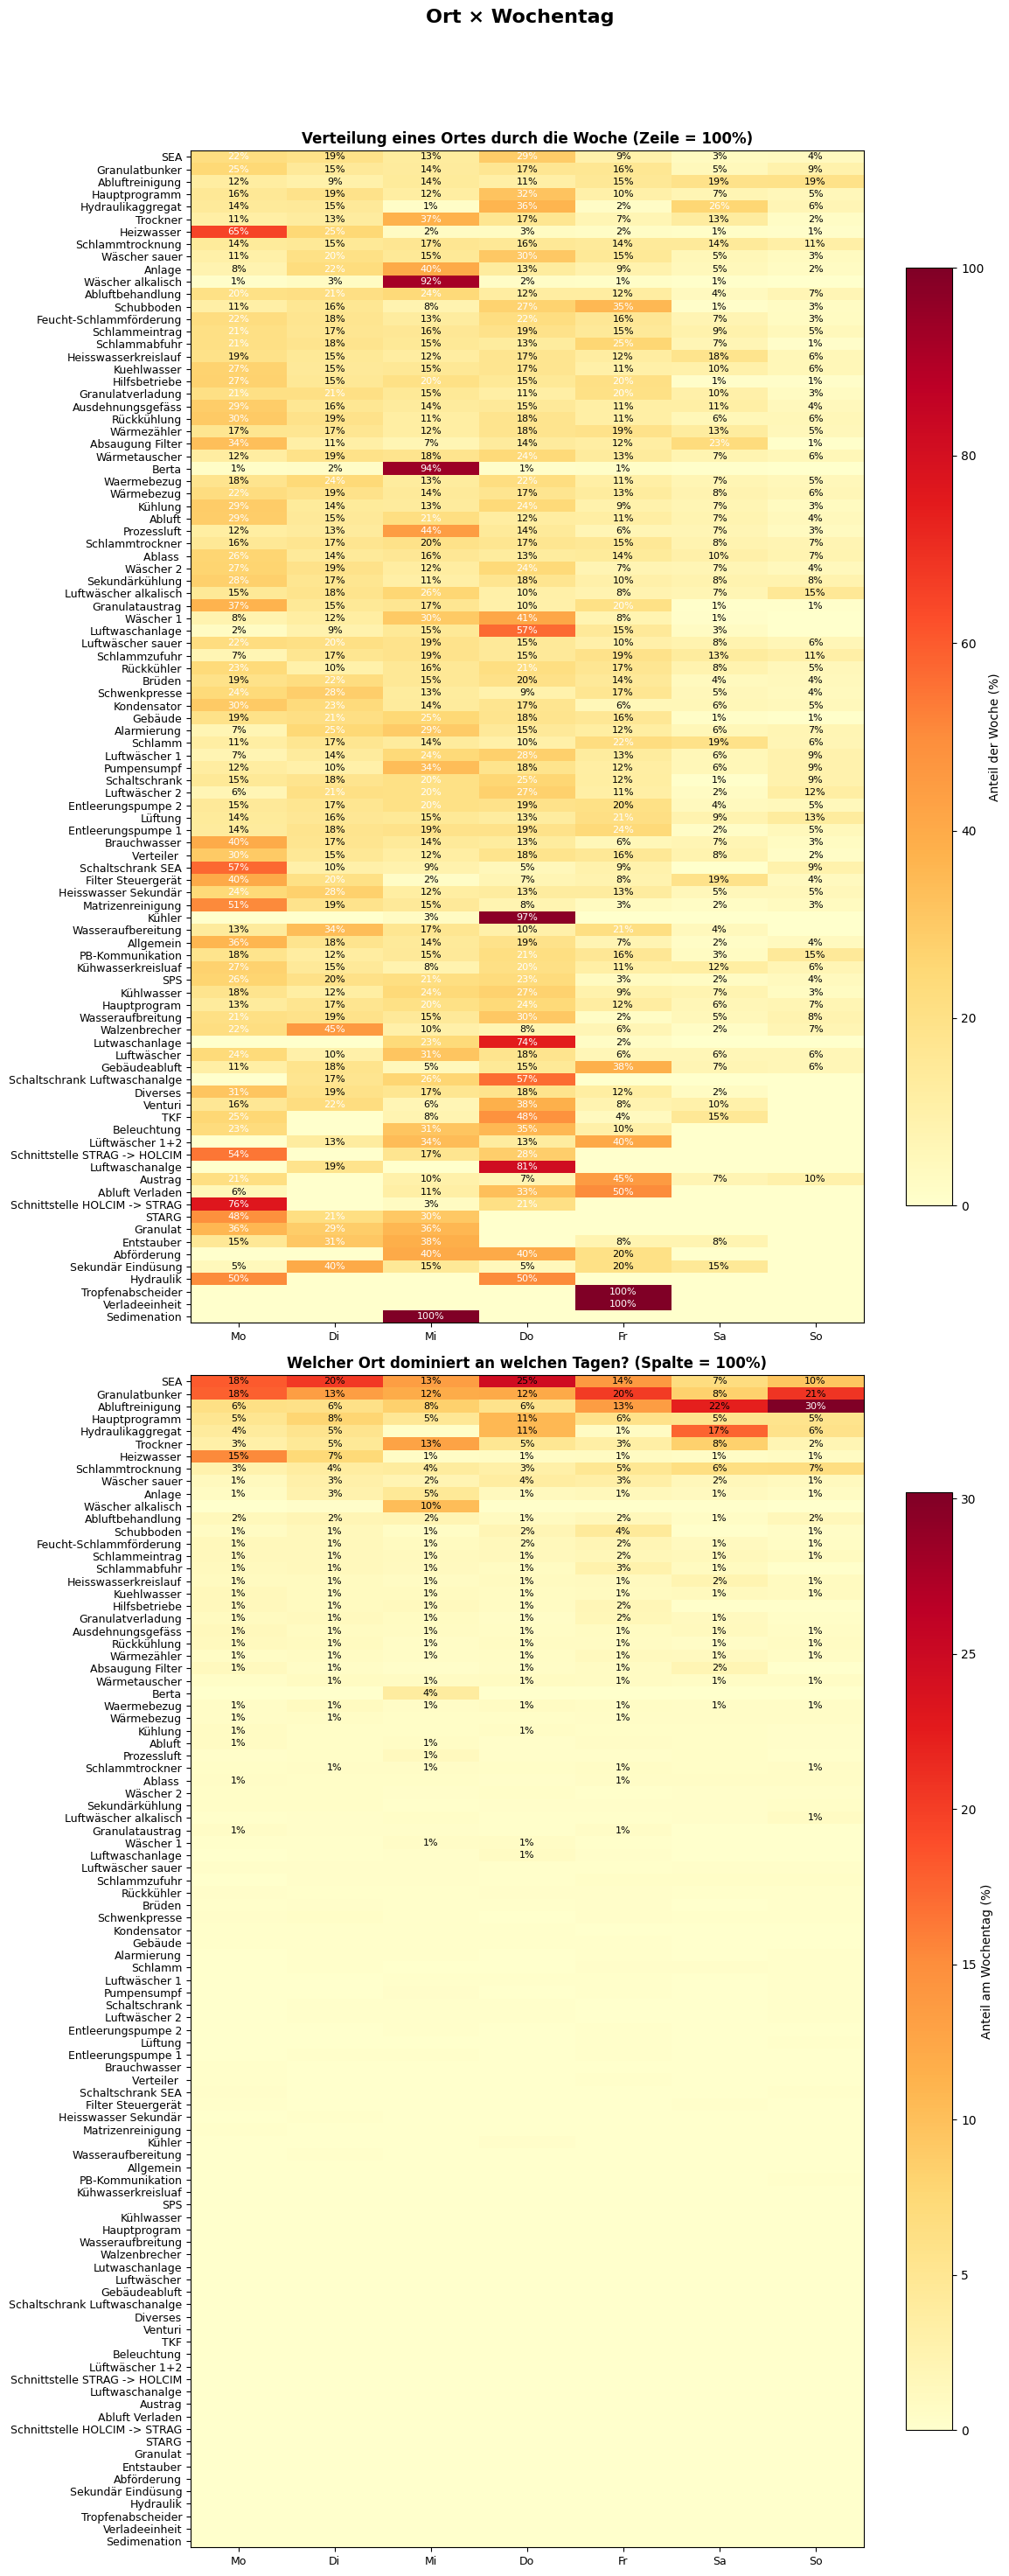

In [115]:
# Wöchentliche verteilung der Einträge pro Ort
wochentag_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wochentag_labels = ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"]

df["Datum"] = pd.to_datetime(df["Datum"])
df["Wochentag"] = df["Datum"].dt.day_name()
df["Stunde"] = df["Datum"].dt.hour

df_ort = df[(df["Ort"].notna()) & (~df["Ort"].isin(["AUTO"]))]

fig, axes = plt.subplots(2, 1, figsize=(12, 30))

# === Oben: Pro Zeile (Wann arbeite ich?) ===
ct = pd.crosstab(df_ort["Ort"], df_ort["Wochentag"])
ct = ct.reindex(columns=wochentag_order, fill_value=0)
ct.columns = wochentag_labels
ort_order = ct.sum(axis=1).sort_values(ascending=False).index
ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100

im1 = axes[0].imshow(ct_norm.loc[ort_order].values, cmap="YlOrRd", aspect="auto")
axes[0].set_yticks(range(len(ort_order)))
axes[0].set_yticklabels(ort_order, fontsize=9)
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(wochentag_labels, fontsize=9)

for i in range(len(ort_order)):
    for j in range(7):
        val = ct_norm.loc[ort_order].iloc[i, j]
        if val >= 0.5:
            color = "white" if val > 20 else "black"
            axes[0].text(j, i, f"{val:.0f}%", ha="center", va="center", fontsize=8, color=color)

cbar1 = plt.colorbar(im1, ax=axes[0], shrink=0.8)
cbar1.set_label("Anteil der Woche (%)")
axes[0].set_title("Verteilung eines Ortes durch die Woche (Zeile = 100%)", fontsize=12, fontweight="bold")

# === Unten: Pro Spalte (Wer dominiert wann?) ===
ct_norm_col = ct.div(ct.sum(axis=0), axis=1) * 100

im2 = axes[1].imshow(ct_norm_col.loc[ort_order].values, cmap="YlOrRd", aspect="auto")
axes[1].set_yticks(range(len(ort_order)))
axes[1].set_yticklabels(ort_order, fontsize=9)
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(wochentag_labels, fontsize=9)

for i in range(len(ort_order)):
    for j in range(7):
        val = ct_norm_col.loc[ort_order].iloc[i, j]
        if val >= 0.5:
            color = "white" if val > 25 else "black"
            axes[1].text(j, i, f"{val:.0f}%", ha="center", va="center", fontsize=8, color=color)

cbar2 = plt.colorbar(im2, ax=axes[1], shrink=0.8)
cbar2.set_label("Anteil am Wochentag (%)")
axes[1].set_title("Welcher Ort dominiert an welchen Tagen? (Spalte = 100%)", fontsize=12, fontweight="bold")

plt.suptitle("Ort × Wochentag", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

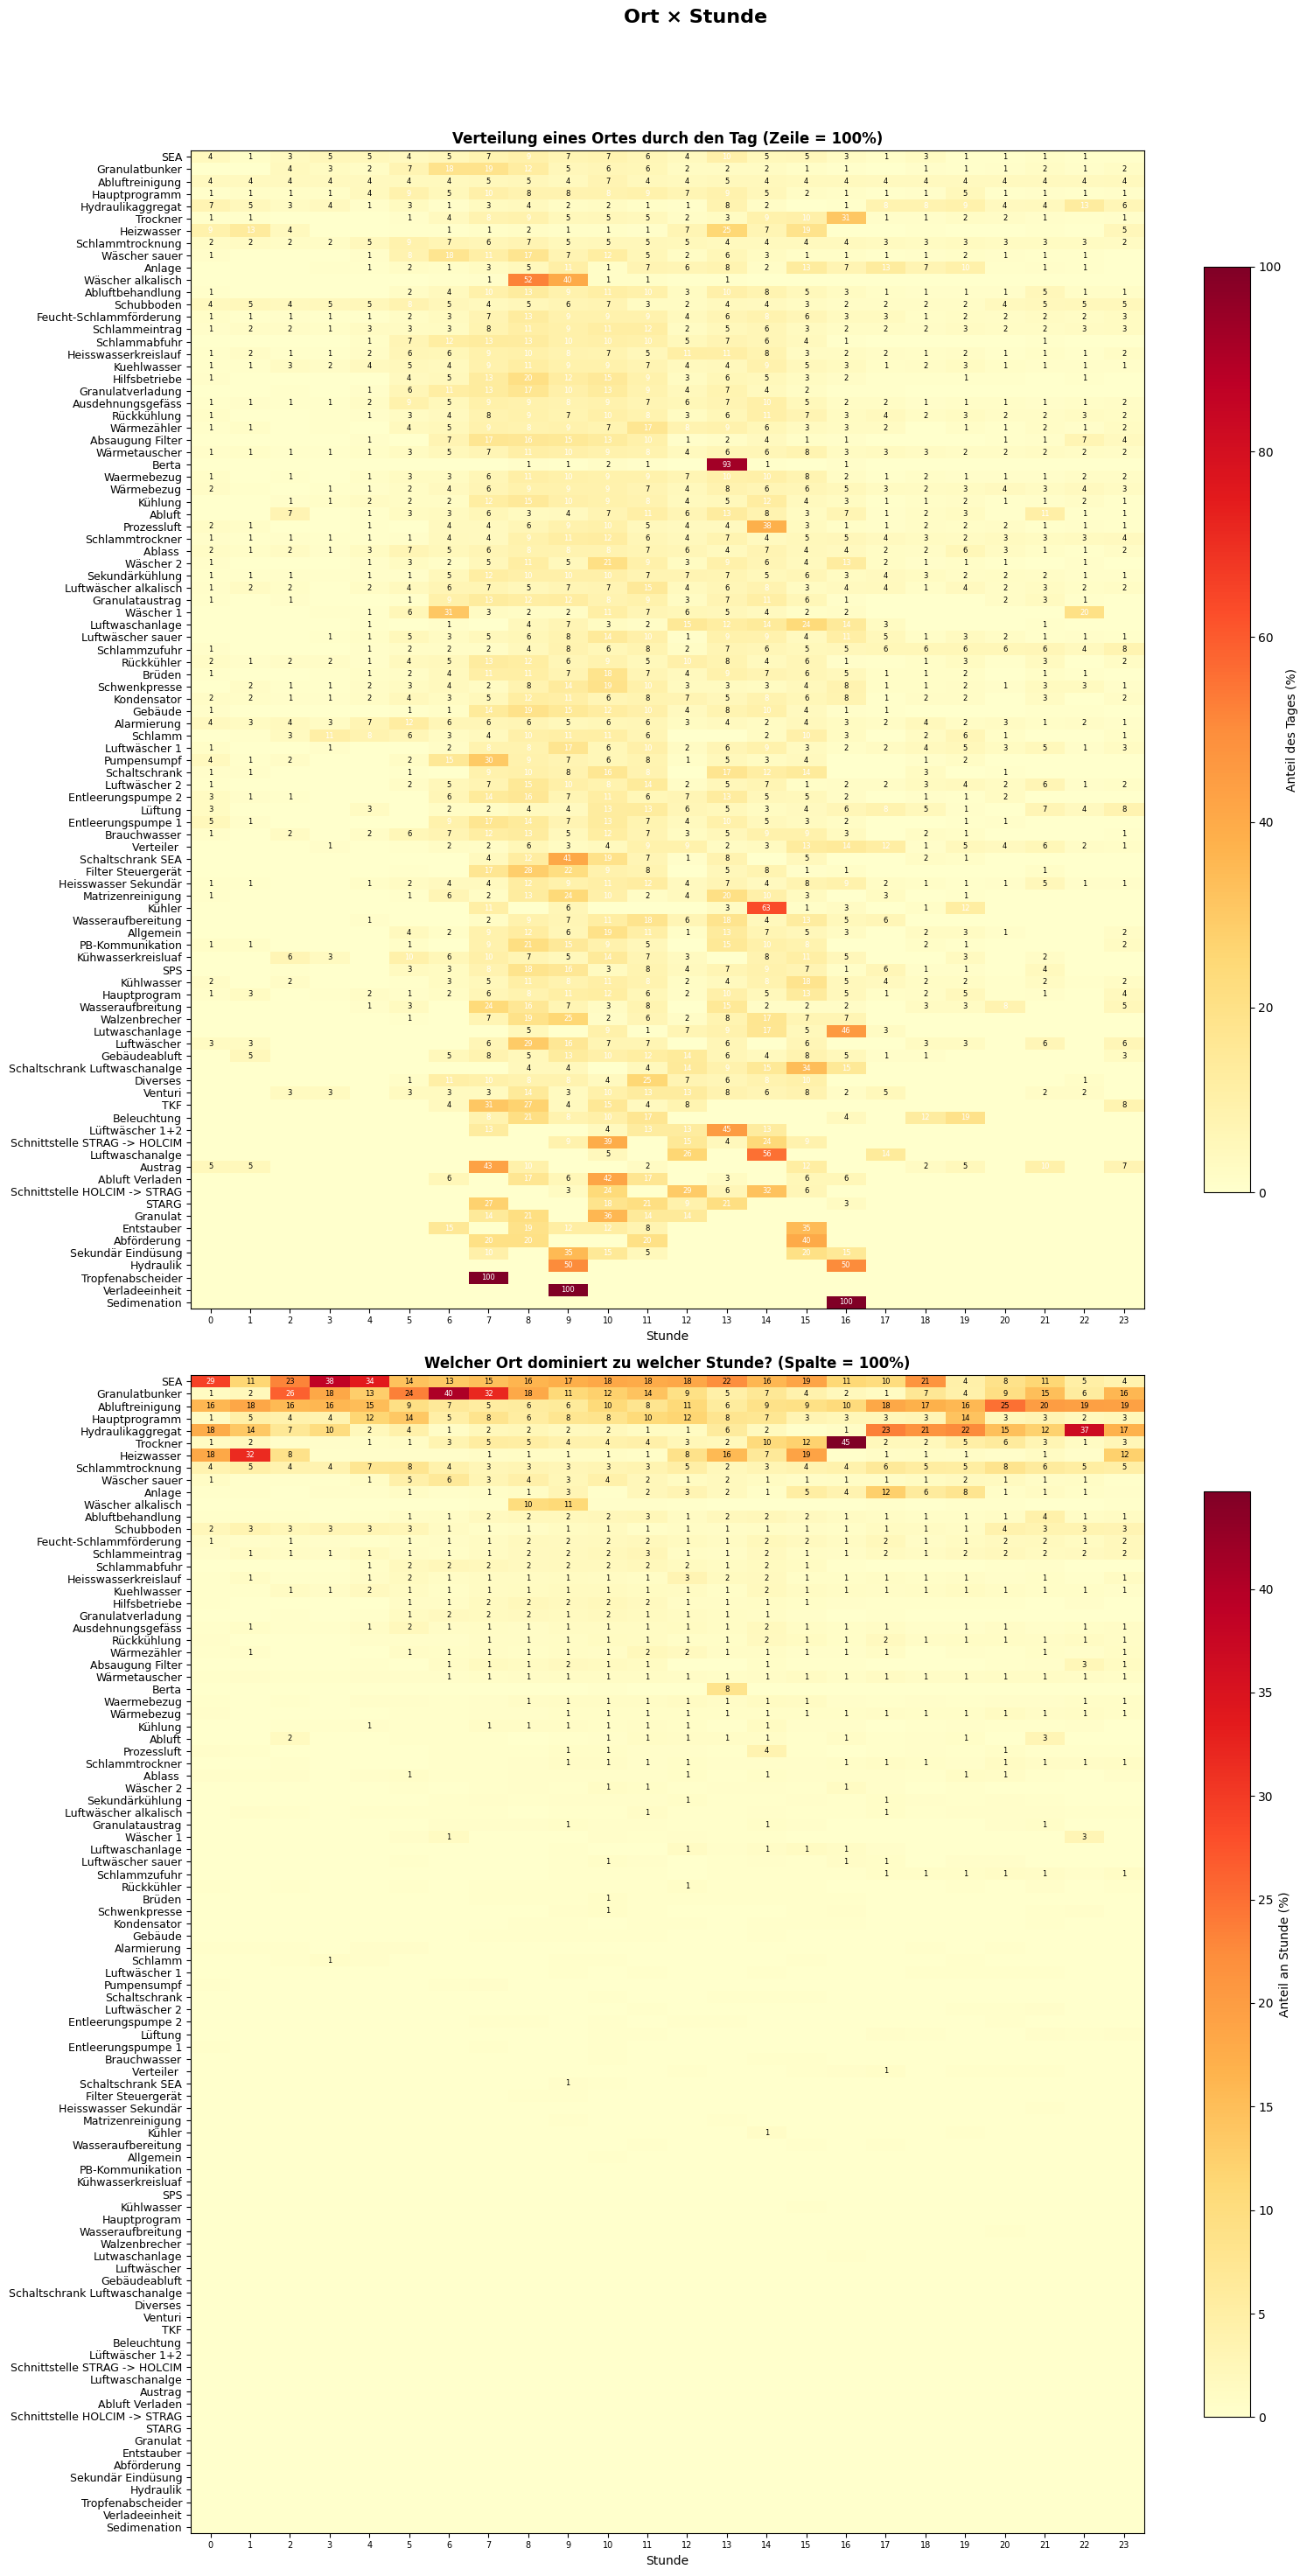

In [116]:
# Tägliche verteilung der Einträge pro Ort
fig, axes = plt.subplots(2, 1, figsize=(16, 30))

# === Oben: Pro Zeile (Wann arbeite ich?) ===
ct = pd.crosstab(df_ort["Ort"], df_ort["Stunde"])
ct = ct.reindex(columns=range(24), fill_value=0)
ort_order = ct.sum(axis=1).sort_values(ascending=False).index
ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100

im1 = axes[0].imshow(ct_norm.loc[ort_order].values, cmap="YlOrRd", aspect="auto")
axes[0].set_yticks(range(len(ort_order)))
axes[0].set_yticklabels(ort_order, fontsize=9)
axes[0].set_xticks(range(24))
axes[0].set_xticklabels(range(24), fontsize=7)
axes[0].set_xlabel("Stunde")

for i in range(len(ort_order)):
    for j in range(24):
        val = ct_norm.loc[ort_order].iloc[i, j]
        if val >= 0.5:
            color = "white" if val > 8 else "black"
            axes[0].text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=6, color=color)

cbar1 = plt.colorbar(im1, ax=axes[0], shrink=0.8)
cbar1.set_label("Anteil des Tages (%)")
axes[0].set_title(
    "Verteilung eines Ortes durch den Tag (Zeile = 100%)", fontsize=12, fontweight="bold"
)

# === Unten: Pro Spalte (Wer dominiert wann?) ===
ct_norm_col = ct.div(ct.sum(axis=0), axis=1) * 100

im2 = axes[1].imshow(ct_norm_col.loc[ort_order].values, cmap="YlOrRd", aspect="auto")
axes[1].set_yticks(range(len(ort_order)))
axes[1].set_yticklabels(ort_order, fontsize=9)
axes[1].set_xticks(range(24))
axes[1].set_xticklabels(range(24), fontsize=7)
axes[1].set_xlabel("Stunde")

for i in range(len(ort_order)):
    for j in range(24):
        val = ct_norm_col.loc[ort_order].iloc[i, j]
        if val >= 0.5:
            color = "white" if val > 25 else "black"
            axes[1].text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=6, color=color)

cbar2 = plt.colorbar(im2, ax=axes[1], shrink=0.8)
cbar2.set_label("Anteil an Stunde (%)")
axes[1].set_title(
    "Welcher Ort dominiert zu welcher Stunde? (Spalte = 100%)", fontsize=12, fontweight="bold"
)

plt.suptitle("Ort × Stunde", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()